# ¿Cuántos símbolos hacen falta para decidir?
## Monitoreo secuencial de traslape espectral en señales ópticas IQ con Calibración de Creencias y Parada Óptima por SARSA

**Proyecto final — Sistemas de Decisión Autónoma bajo Incertidumbre**  
**Ruta metodológica:** Inferencia bayesiana secuencial (verosimilitud atemperada) + Diagnóstico de calibración (Brier y diagrama de confiabilidad) + Políticas de parada secuencial (SARSA multi-semilla vs. ventana fija vs. umbral de confianza)  
**Escenario principal:** 32 GBd, back-to-back (`32G_B2B`)

Este notebook documenta la formulación, implementación y validación experimental del sistema de monitoreo espectral autónomo. El objetivo es resolver el problema de parada óptima: decidir secuencialmente cuántos bloques de símbolos observar antes de declarar la presencia ($z=1$) o ausencia ($z=0$) de traslape espectral, minimizando la suma del costo de observación y los costos de decisión errónea.


## Mapa del notebook

1. **Entorno y configuración:** Carga de módulos, lectura de configuración YAML y definición de costos de decisión.
2. **Parámetros y ampliación de separaciones:** Selección balanceada de separaciones alrededor de la frontera geométrica ($35.2$ GHz): `[34.0, 34.5, 35.0, 35.5, 36.0, 37.5] GHz`.
3. **Inventario de datos y consistencia:** Extracción y verificación de condiciones compartidas entre canciones.
4. **Inspección de IQ y Feature EVM:** Análisis físico de la constelación 16-QAM y extracción del Error Vector Magnitude (EVM) respecto al símbolo más cercano como feature discriminativa de traslape.
5. **Partición estricta por adquisiciones:** Asignación independiente de canciones (`song1` KDE, `song2` SARSA train, `song3` validación, `song4` prueba) garantizando cero fuga de información.
6. **Ajuste del banco KDE por condición:** Densidades 2D sobre `song1` y prior uniforme por clase.
7. **Aumento de episodios sin cruce:** Extracción de múltiples ventanas desplazadas por captura para enriquecer la experiencia de aprendizaje.
8. **Diagnóstico y Calibración del posterior antes de SARSA:**
   - 8.1 Diagnóstico de saturación y sobreconfianza del posterior original (Brier Score y diagrama de confiabilidad).
   - 8.2 Búsqueda en grilla / validación cruzada de $h$ y verosimilitud atemperada (factor de tamaño efectivo).
   - 8.3 Trazas de creencia calibrada a lo largo del tiempo.
9. **MDP aproximado:** Espacio de estados $(k, 	ext{bin}(b_k))$, acciones y recompensas de observación y decisión.
10. **Entrenamiento de SARSA multi-semilla:** Aprendizaje on-policy con reporte de media y dispersión ($\pm 1	ext{ std}$) sobre múltiples semillas.
11. **Políticas de referencia:** Calibración de ventana fija y umbral de confianza bayesiano en validación (`song3`).
12. **Evaluación rigurosa en `song4`:** Comparación de políticas con estadísticas agregadas (media ± std).
13. **Comparación a costo y error equivalentes:** Análisis de la frontera de Pareto (error vs latencia y costo total esperado).
14. **Lectura crítica y artefactos:** Síntesis técnica y próximos pasos.


## 1. Entorno y configuración

Se importan las bibliotecas numéricas y los módulos estructurados del paquete `src/`: inventario, cargador de adquisiciones, banco de densidades KDE y actualización bayesiana secuencial.


In [1]:
import json
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

# Permite ejecutar el notebook desde la raíz del repo o desde notebooks/.
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(
    (
        p
        for p in candidates
        if (p / "src").is_dir() and (p / "configs/experiment.yaml").is_file()
    ),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        "No encuentro la raíz del proyecto (src/ y configs/experiment.yaml)."
    )

sys.path.insert(0, str(ROOT))
from src.bayes.update import (
    accumulate_loglik,
    build_prior,
    compute_brier_score,
    overlap_prob,
    posterior_from_loglik,
    reliability_curve,
)
from src.data.inventory import InventoryConfig, build_inventory, summarize
from src.data.loader import load_capture, load_inventory, split_into_blocks
from src.kde.bank import ConditionKDE, KDEBank, build_bank

DATA_DIR = ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

SEED = 7
np.random.seed(SEED)
print("Raíz del proyecto:", ROOT)
print("Carpeta de datos procesados:", PROCESSED_DIR)


Raíz del proyecto: /home/oagr/Documentos/UdeA/Semestre 2026-2/SDAI/Proyecto Final
Carpeta de datos procesados: /home/oagr/Documentos/UdeA/Semestre 2026-2/SDAI/Proyecto Final/data/processed


## 2. Parámetros del experimento y ampliación de separaciones

### Ampliación del conjunto de separaciones
En lugar de limitarse a sólo dos separaciones ($35.0$ y $35.5$ GHz), ampliamos a un conjunto balanceado alrededor de la frontera física nominal:
$$B_{nom} = R_s (1 + 
ho) = 32(1 + 0.1) = 35.2\;\mathrm{GHz}$$

- **Clase con traslape ($z=1$, $\mathrm{ChSp} < 35.2\;\mathrm{GHz}$):** $34.0$, $34.5$ y $35.0\;\mathrm{GHz}$ (distintos grados de interferencia inter-canal).
- **Clase sin traslape ($z=0$, $\mathrm{ChSp} > 35.2\;\mathrm{GHz}$):** $35.5$, $36.0$ y $37.5\;\mathrm{GHz}$ (márgenes crecientes de guarda).

Esto permite evaluar el monitor ante diferentes niveles de solape y OSNR, enriqueciendo sustancialmente el problema de decisión.


In [2]:
with open(ROOT / "configs/experiment.yaml", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)

data_cfg = cfg["data"]
RS_GBAUD = float(data_cfg["rs_gbaud"])
ROLLOFF = float(data_cfg["rolloff"])
BOUNDARY_GHZ = RS_GBAUD * (1.0 + ROLLOFF)  # 35.2 GHz

# Parámetros del bloque y horizonte secuencial
BLOCK_SIZE = 100  # m símbolos por bloque
MAX_BLOCKS = 10  # horizonte máximo de decisión: 10 bloques (1000 símbolos)
KDE_CENTERS = 150  # centros por condición para el banco KDE
BANDWIDTH = (
    0.20  # ancho de banda h calibrado (mayor suavizado para evitar colapso de densidad)
)
TEMPERATURE = (
    50.0  # factor de atemperamiento / tamaño efectivo para mitigar sobreconfianza
)
N_SLICES_PER_CAPTURE = (
    5  # ventanas desplazadas no solapadas por captura para multiplicar episodios
)

# Separaciones seleccionadas
FOCUS_CHSP = [
    28.5,
    29.0,
    29.5,
    30.0,
    30.5,
    31.0,
    31.5,
    32.0,
    32.5,
    33.0,
    33.5,
    34.0,
    34.5,
    35.0,
    35.5,
    36.0,
    37.5,
]

# Costos ilustrativos para el trade-off de decisión
C_FN = 10.0  # Costo de falso negativo (declarar sin traslape cuando sí hay)
C_FP = 5.0  # Costo de falso positivo (declarar traslape cuando no hay)
C_OBS = 0.05  # Costo por bloque observado adicional
gamma = 1.0  # Horizonte finito: sin descuento temporal

print(f"Ancho nominal (frontera): {BOUNDARY_GHZ:.1f} GHz")
print(f"Separaciones de estudio: {FOCUS_CHSP}")
print(
    f"Bloque: {BLOCK_SIZE} símbolos; Horizonte: {MAX_BLOCKS} bloques ({BLOCK_SIZE * MAX_BLOCKS} símbolos)"
)
print(f"KDE: {KDE_CENTERS} centros, h={BANDWIDTH}, Temperatura={TEMPERATURE}")
print(f"Costos: C_FN={C_FN}, C_FP={C_FP}, C_OBS={C_OBS}")


Ancho nominal (frontera): 35.2 GHz
Separaciones de estudio: [28.5, 29.0, 29.5, 30.0, 30.5, 31.0, 31.5, 32.0, 32.5, 33.0, 33.5, 34.0, 34.5, 35.0, 35.5, 36.0, 37.5]
Bloque: 100 símbolos; Horizonte: 10 bloques (1000 símbolos)
KDE: 150 centros, h=0.2, Temperatura=50.0
Costos: C_FN=10.0, C_FP=5.0, C_OBS=0.05


## 3. Inventario de los archivos y condiciones compartidas

Construimos el inventario completo y filtramos las condiciones que tienen réplica en las 4 canciones (`song1` a `song4`). Así garantizamos que las condiciones evaluadas en prueba estén presentes en el banco de entrenamiento.


In [3]:
inventory_cfg = InventoryConfig.from_yaml(ROOT / "configs/experiment.yaml")
inv = build_inventory(inventory_cfg)
inv.to_csv(PROCESSED_DIR / "inventory.csv", index=False)


def song_from_capture_id(capture_id):
    name = str(capture_id).rsplit("/", 1)[-1]
    return name.split("_", 1)[0]


inv["song"] = inv["capture_id"].map(song_from_capture_id)
focus_inv = inv[
    inv["scenario"].eq("32G_B2B")
    & inv["chsp_ghz"].isin(FOCUS_CHSP)
    & inv["label_geometrica"].notna()
].copy()

# Encontrar condiciones (ChSp, OSNR) exactamente compartidas por las cuatro canciones
required_songs = ["song1", "song2", "song3", "song4"]
condition_sets = {
    song: set(
        zip(
            focus_inv.loc[focus_inv["song"].eq(song), "chsp_ghz"].astype(float),
            focus_inv.loc[focus_inv["song"].eq(song), "osnr_db"].round(2),
        )
    )
    for song in required_songs
}
common_conditions = set.intersection(*(condition_sets[song] for song in required_songs))
focus_inv = focus_inv[
    focus_inv.apply(
        lambda r: (
            (float(r["chsp_ghz"]), round(float(r["osnr_db"]), 2)) in common_conditions
        ),
        axis=1,
    )
].copy()

counts = (
    focus_inv.groupby(["chsp_ghz", "song"], observed=True)
    .size()
    .unstack(fill_value=0)
    .sort_index()
)
display(counts)
print(
    f"Total de condiciones únicas (ChSp, OSNR) compartidas por las 4 canciones: {len(common_conditions)}"
)
print(f"Total de adquisiciones en el dataset balanceado: {len(focus_inv)}")


song,song1,song2,song3,song4
chsp_ghz,,,,
30.0,1,1,1,1
30.5,4,4,4,4
31.0,4,4,4,4
31.5,5,5,5,5
32.0,5,5,5,5
32.5,5,5,5,5
33.0,8,8,8,8
33.5,9,9,9,9
34.0,11,11,11,11


Total de condiciones únicas (ChSp, OSNR) compartidas por las 4 canciones: 99
Total de adquisiciones en el dataset balanceado: 396


## 4. Inspección de IQ y Feature EVM respecto al símbolo más cercano

### 4.1 Constelación RX cruda
En señales ópticas coherentes con modulación 16-QAM, la constelación normalizada teórica contiene 16 puntos distribuidos en un reticulado bidimensional con coordenadas $I, Q \in \{\pm 1, \pm 3\}/\sqrt{10}$.


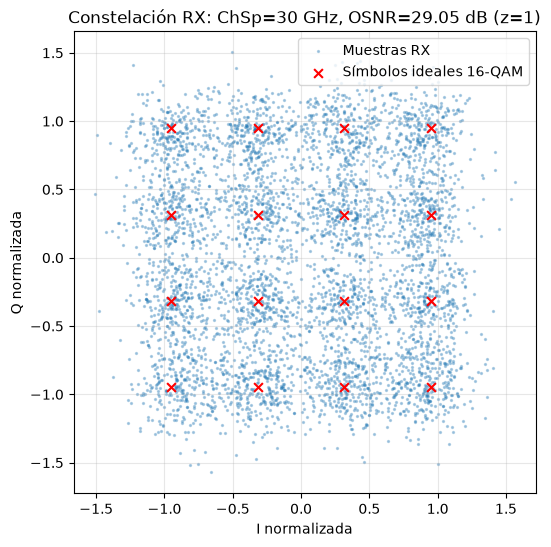

In [4]:
example_row = focus_inv[focus_inv["label_geometrica"] == 1].iloc[0]
example_capture = load_capture(example_row)
n_show = min(5000, len(example_capture.y))
y_show = example_capture.y[:n_show]

# Reticulado teórico 16-QAM normalizado
grid_1d = np.array([-3.0, -1.0, 1.0, 3.0]) / np.sqrt(10.0)
constellation = np.array([i + 1j * q for i in grid_1d for q in grid_1d])

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(
    y_show.real, y_show.imag, s=2, alpha=0.3, color="tab:blue", label="Muestras RX"
)
ax.scatter(
    constellation.real,
    constellation.imag,
    s=40,
    color="red",
    marker="x",
    label="Símbolos ideales 16-QAM",
)
ax.set(
    title=f"Constelación RX: ChSp={example_capture.chsp_ghz:g} GHz, OSNR={example_capture.osnr_db:g} dB (z={example_capture.label})",
    xlabel="I normalizada",
    ylabel="Q normalizada",
)
ax.set_aspect("equal")
ax.grid(alpha=0.3)
ax.legend(loc="upper right")
plt.show()


### 4.2 Feature más informativa para el traslape: Error Vector Magnitude (EVM) por bloque

#### Justificación física
El plano $IQ$ crudo dispersa los símbolos en 16 nubes aisladas. Cuando la KDE 2D opera directamente sobre $(I, Q)$, gran parte de la varianza estimada refleja la posición aleatoria de cada símbolo dentro de la constelación y el ruido térmico local, en lugar de la firma específica del traslape.

Físicamente, el traslape espectral introduce interferencia inter-canal (crosstalk). Esta interferencia añade una perturbación estocástica de cola pesada que ensancha las nubes y desplaza las muestras respecto al símbolo transmitido. Por tanto, la métrica directa de degradación es la distancia al símbolo más cercano del reticulado:
$$e_i = \min_{s \in \mathcal{C}_{16}} |y_i - s|$$

Para un bloque de $m$ símbolos, el **EVM del bloque** (Error Vector Magnitude) se define como:
$$\mathrm{EVM}_{\mathrm{bloque}} = \sqrt{\frac{1}{m} \sum_{i=1}^m e_i^2}$$

A continuación calculamos y comparamos el EVM para capturas con y sin traslape a lo largo de diversos niveles de OSNR.


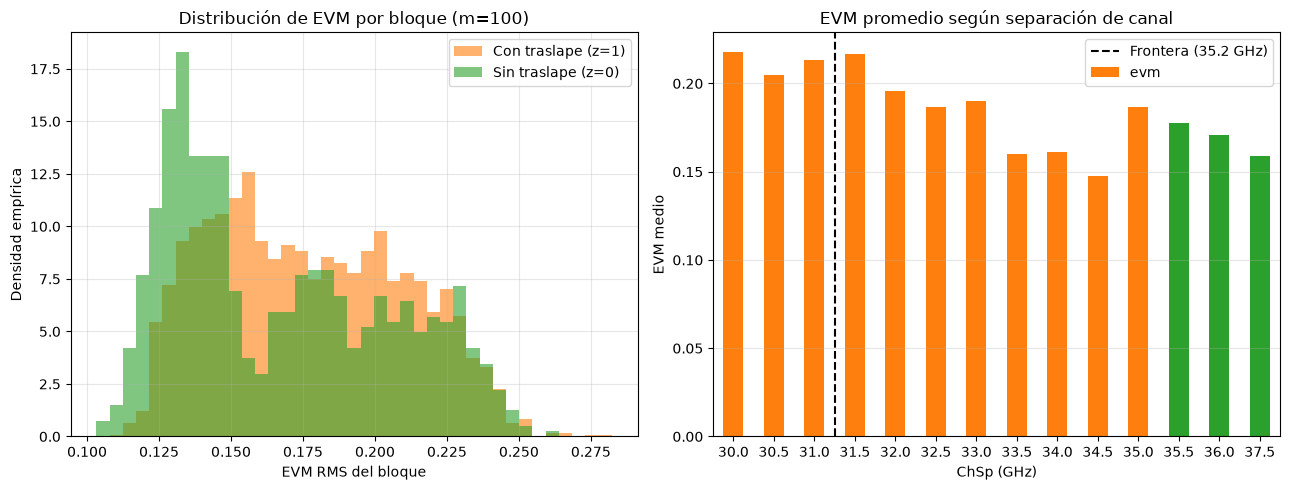

Resumen de EVM por clase:


,count,mean,std,min,25%,50%,75%,max
z,,,,,,,,
0,880.0,0.1672,0.0378,0.1032,0.1343,0.1581,0.1991,0.2621
1,2320.0,0.1768,0.0333,0.1104,0.1489,0.1739,0.2032,0.2822


In [5]:
def compute_evm_errors(y):
    """Calcula la distancia de cada muestra al símbolo 16-QAM más cercano."""
    return np.min(np.abs(y[:, None] - constellation[None, :]), axis=1)


def compute_block_evm(y, block_size=100):
    """Calcula el EVM RMS por bloques de m símbolos."""
    n_blocks = len(y) // block_size
    evm_blocks = []
    for i in range(n_blocks):
        blk = y[i * block_size : (i + 1) * block_size]
        errs = compute_evm_errors(blk)
        evm_blocks.append(np.sqrt(np.mean(errs**2)))
    return np.array(evm_blocks)


# Comparar distribución de EVM entre clases sobre una muestra de capturas
evm_records = []
for _, row in focus_inv.sample(min(80, len(focus_inv)), random_state=SEED).iterrows():
    cap = load_capture(row)
    b_evm = compute_block_evm(cap.y[:4000], block_size=BLOCK_SIZE)
    for val in b_evm:
        evm_records.append(
            {
                "chsp_ghz": row["chsp_ghz"],
                "osnr_db": row["osnr_db"],
                "z": int(row["label_geometrica"]),
                "evm": val,
            }
        )

df_evm_sample = pd.DataFrame(evm_records)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Histograma de EVM por clase
ax = axes[0]
bins = np.linspace(df_evm_sample["evm"].min(), df_evm_sample["evm"].max(), 40)
ax.hist(
    df_evm_sample[df_evm_sample["z"] == 1]["evm"],
    bins=bins,
    alpha=0.6,
    density=True,
    color="tab:orange",
    label="Con traslape (z=1)",
)
ax.hist(
    df_evm_sample[df_evm_sample["z"] == 0]["evm"],
    bins=bins,
    alpha=0.6,
    density=True,
    color="tab:green",
    label="Sin traslape (z=0)",
)
ax.set(
    title="Distribución de EVM por bloque (m=100)",
    xlabel="EVM RMS del bloque",
    ylabel="Densidad empírica",
)
ax.grid(alpha=0.3)
ax.legend()

# EVM medio vs ChSp
ax = axes[1]
evm_by_chsp = df_evm_sample.groupby("chsp_ghz")["evm"].mean()
colors = ["tab:orange" if c < BOUNDARY_GHZ else "tab:green" for c in evm_by_chsp.index]
evm_by_chsp.plot.bar(ax=ax, color=colors, rot=0)
ax.axvline(
    2.5, color="black", linestyle="--", label=f"Frontera ({BOUNDARY_GHZ:.1f} GHz)"
)
ax.set(
    title="EVM promedio según separación de canal",
    xlabel="ChSp (GHz)",
    ylabel="EVM medio",
)
ax.grid(axis="y", alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

print("Resumen de EVM por clase:")
display(df_evm_sample.groupby("z")["evm"].describe().round(4))


## 5. Partición estricta por adquisiciones completas

Para evitar cualquier forma de memorización o fuga de datos:
1. `song1`: Ajuste exclusivo del banco KDE por condición.
2. `song2`: Entrenamiento de la política de parada con SARSA.
3. `song3`: Validación cruzada, selección de hiperparámetros ($h$, $T$, umbrales).
4. `song4`: Evaluación final y prueba congelada.

> **Regla de higiene de partición:** Toda ventana, bloque o trayectoria derivada de una captura queda estrictamente confinada a la partición de dicha captura. Nunca se mezclan fragmentos de una captura entre particiones.


In [6]:
train_kde = focus_inv[focus_inv["song"].eq("song1")].copy()
train_policy = focus_inv[focus_inv["song"].eq("song2")].copy()
validation = focus_inv[focus_inv["song"].eq("song3")].copy()
test = focus_inv[focus_inv["song"].eq("song4")].copy()

split_summary = pd.DataFrame(
    {
        "Partición": [
            "KDE train (song1)",
            "SARSA train (song2)",
            "Validación (song3)",
            "Prueba (song4)",
        ],
        "Capturas": [len(train_kde), len(train_policy), len(validation), len(test)],
        "Traslape (z=1)": [
            (train_kde["label_geometrica"] == 1).sum(),
            (train_policy["label_geometrica"] == 1).sum(),
            (validation["label_geometrica"] == 1).sum(),
            (test["label_geometrica"] == 1).sum(),
        ],
        "Sin traslape (z=0)": [
            (train_kde["label_geometrica"] == 0).sum(),
            (train_policy["label_geometrica"] == 0).sum(),
            (validation["label_geometrica"] == 0).sum(),
            (test["label_geometrica"] == 0).sum(),
        ],
    }
)
display(split_summary)
assert all(len(p) > 0 for p in [train_kde, train_policy, validation, test]), (
    "Error en particiones."
)


,Partición,Capturas,Traslape (z=1),Sin traslape (z=0)
0,KDE train (song1),99,68,31
1,SARSA train (song2),99,68,31
2,Validación (song3),99,68,31
3,Prueba (song4),99,68,31


## 6. Ajustar el banco KDE por condición (`song1`)

Ajustamos un `ConditionKDE` para cada tupla $c = (\mathrm{ChSp}, \mathrm{OSNR})$ utilizando únicamente las señales de `song1`. A continuación, definimos el prior uniforme por clase (50 % a $z=1$ y 50 % a $z=0$) para evitar cualquier sesgo por desbalance en el número de condiciones registradas.


In [7]:
labels = {}
for _, row in focus_inv.drop_duplicates(["chsp_ghz", "osnr_db"]).iterrows():
    labels[(float(row["chsp_ghz"]), float(row["osnr_db"]))] = int(
        row["label_geometrica"]
    )

bank = build_bank(
    inventory=inv,
    train_capture_ids=train_kde["capture_id"].tolist(),
    bandwidth=BANDWIDTH,
    subsample=KDE_CENTERS,
    seed=SEED,
)
print("Condiciones KDE en el banco:", len(bank.keys()))

prior = build_prior(bank, labels, prior_class=0.5)
print(f"Suma total del prior: {sum(prior.values()):.4f}")
print(
    f"Prior total de traslape P(z=1): {sum(p for c, p in prior.items() if labels.get(c) == 1):.4f}"
)
print(
    f"Prior total sin traslape P(z=0): {sum(p for c, p in prior.items() if labels.get(c) == 0):.4f}"
)


KDE por condición:   0%|          | 0/99 [00:00<?, ?it/s]

KDE por condición: 100%|██████████| 99/99 [00:00<00:00, 173.92it/s]

Condiciones KDE en el banco: 99
Suma total del prior: 1.0000
Prior total de traslape P(z=1): 0.5000
Prior total sin traslape P(z=0): 0.5000


## 7. Aumento de episodios: Ventanas desplazadas sin mezclar capturas

Cada archivo de captura contiene $\sim 39{,}500$ símbolos. Un episodio de parada tiene un horizonte de $MAX\_BLOCKS = 10$ bloques ($1{,}000$ símbolos). 

En lugar de extraer una sola trayectoria por archivo, extraemos $N_{slices} = 5$ segmentos no solapados de distintas partes de la captura (por ejemplo, índices $0..1000$, $1000..2000$, etc.). Para acelerar el cálculo, evaluamos la matriz de log-densidades $\mathcal{L} \in \mathbb{R}^{N \times C}$ de forma vectorizada por captura y luego calculamos las actualizaciones bayesianas de cada segmento.


In [29]:
# =====================================================================
# PASO 1 — Diagnóstico: ¿qué feature separa traslape de no traslape?
# Pegar como celda nueva después de la sección 7 del notebook.
# Usa: inv, load_capture, constellation, song_from_capture_id,
#      PROCESSED_DIR, BOUNDARY_GHZ, SEED
# =====================================================================
import numpy as np
import pandas as pd
from scipy.stats import rankdata, kurtosis

LAGS = (1, 2, 3, 5)


def error_vector(y):
    """Error complejo respecto al símbolo 16-QAM más cercano."""
    idx = np.argmin(np.abs(y[:, None] - constellation[None, :]), axis=1)
    return y - constellation[idx]


def error_features(y):
    e = error_vector(y)
    p = np.mean(np.abs(e) ** 2)
    feats = {"evm2": p}
    # Autocorrelación normalizada del error: ~0 si el ruido es blanco (ASE),
    # > 0 si hay interferencia coloreada de un canal vecino (hipótesis a verificar).
    for lag in LAGS:
        feats[f"acf{lag}"] = np.real(np.sum(e[:-lag] * np.conj(e[lag:]))) / np.sum(
            np.abs(e) ** 2
        )
    # Forma de la distribución del error (la interferencia suele dar colas más pesadas).
    feats["kurt_I"] = kurtosis(e.real)
    feats["kurt_Q"] = kurtosis(e.imag)
    return feats


def auc(score, label):
    """AUC por rangos (Mann-Whitney). 0.5 = azar, 1 = separación perfecta."""
    score, label = np.asarray(score), np.asarray(label)
    n1, n0 = (label == 1).sum(), (label == 0).sum()
    if n1 == 0 or n0 == 0:
        return np.nan
    r = rankdata(score)
    return (r[label == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


# ---- 1) Features por captura (todas las del escenario, como en tu celda 20) ----
inv_all = inv[inv["scenario"].eq("32G_B2B")].copy()
inv_all["song"] = inv_all["capture_id"].map(song_from_capture_id)

rows = []
for _, r in inv_all.iterrows():
    y = load_capture(r).y
    rows.append(
        {
            "song": r["song"],
            "chsp": float(r["chsp_ghz"]),
            "osnr": float(r["osnr_db"]),
            "z": int(r["label_geometrica"]),
            **error_features(y),
        }
    )
feat = pd.DataFrame(rows)
feat.to_csv(PROCESSED_DIR / "features_por_captura.csv", index=False)

# Residuo de EVM² tras quitar el OSNR (solo referencia física, NO usable en despliegue)
feat["noise"] = 10 ** (-feat.osnr / 10)
base = feat[feat.chsp >= 36]
a, b = np.polyfit(base.noise, base.evm2, 1)
feat["resid"] = feat.evm2 - (a * feat.noise + b)

# ---- 2) Promedio por separación de canal ----
cols = ["resid", "acf1", "acf2", "acf3", "acf5", "kurt_I", "kurt_Q"]
print("Media de cada feature por ChSp (¿dónde se vuelve indistinguible?):")
display(feat.groupby("chsp")[cols].mean().round(4))

# ---- 3) AUC por feature en tres escenarios ----
groups = {
    "Detectable: ChSp<=33 vs z=0": feat[(feat.chsp <= 33.0) | (feat.z == 0)],
    "Frontera: 34-35 vs z=0": feat[feat.chsp.between(34.0, 35.0) | (feat.z == 0)],
    "Etiqueta completa (z=1 vs z=0)": feat,
}
feats_to_test = ["evm2", "resid", "acf1", "acf2", "acf3", "acf5", "kurt_I", "kurt_Q"]
auc_tab = pd.DataFrame(
    {
        name: {f: auc(df[f], df["z"] if "Frontera" not in name else (df.chsp < BOUNDARY_GHZ).astype(int)) for f in feats_to_test}
        for name, df in groups.items()
    }
)
print("\nAUC por feature (0.5 = azar):")
display(auc_tab.round(3))

# ---- 4) ¿La feature depende del OSNR? (queremos que NO dependa) ----
z0 = feat[feat.z == 0]
print("\nCorrelación con OSNR dentro de z=0 (cercana a 0 = invariante):")
print(z0[feats_to_test].corrwith(z0["osnr"]).round(3).to_string())

# ---- 5) Estabilidad entre canciones (¿generaliza de song1 a song4?) ----
print("\nacf1 medio por canción y ChSp<=32 vs >=35.5:")
tmp = feat.assign(grupo=np.where(feat.chsp <= 32, "traslape fuerte", np.where(feat.chsp >= 35.5, "sin traslape", "intermedio")))
display(tmp.pivot_table(index="grupo", columns="song", values="acf1", aggfunc="mean").round(4))

Media de cada feature por ChSp (¿dónde se vuelve indistinguible?):


,resid,acf1,acf2,acf3,acf5,kurt_I,kurt_Q
chsp,,,,,,,
28.5,0.0510,-0.0648,-0.0020,0.0175,0.0043,-0.3137,-0.3077
29.0,0.0596,0.0027,-0.0677,0.0732,-0.0124,-0.1270,-0.0145
29.5,0.0418,-0.0913,0.0263,-0.0072,-0.0144,-0.3761,-0.3829
30.0,0.0310,-0.2163,0.1504,-0.1183,-0.0690,-0.5526,-0.5528
30.5,0.0272,-0.2278,0.1695,-0.1391,-0.0911,-0.5270,-0.5317
31.0,0.0216,-0.2296,0.1875,-0.1498,-0.1051,-0.4831,-0.4842
31.5,0.0225,-0.2344,0.1797,-0.1507,-0.1024,-0.4957,-0.5008
32.0,0.0172,-0.2269,0.1730,-0.1357,-0.0935,-0.4074,-0.4146
32.5,0.0113,-0.2100,0.1503,-0.1124,-0.0686,-0.3224,-0.3201



AUC por feature (0.5 = azar):


,Detectable: ChSp<=33 vs z=0,Frontera: 34-35 vs z=0,Etiqueta completa (z=1 vs z=0)
evm2,0.801,0.513,0.692
resid,0.959,0.631,0.841
acf1,0.134,0.289,0.199
acf2,0.851,0.560,0.750
acf3,0.060,0.274,0.145
acf5,0.029,0.350,0.161
kurt_I,0.250,0.503,0.348
kurt_Q,0.246,0.513,0.349



Correlación con OSNR dentro de z=0 (cercana a 0 = invariante):
evm2     -0.922
resid    -0.298
acf1     -0.030
acf2      0.341
acf3      0.405
acf5      0.510
kurt_I    0.934
kurt_Q    0.928

acf1 medio por canción y ChSp<=32 vs >=35.5:


song,song1,song2,song3,song4
grupo,,,,
intermedio,-0.1265,-0.1423,-0.1259,-0.1247
sin traslape,-0.0631,-0.0664,-0.0627,-0.0718
traslape fuerte,-0.2238,-0.2092,-0.2110,-0.1984


In [30]:
# =====================================================================
# PASO 2 — Posterior calibrado por regresión logística sobre features
#          acumuladas (acf1, acf2, acf3, acf5, log EVM^2), un modelo por k.
# Reemplaza las secciones 6-8 (banco KDE, episodios, atemperado).
# Usa: train_kde, train_policy, validation, test (sección 5), load_capture,
#      constellation, BLOCK_SIZE, MAX_BLOCKS, N_SLICES_PER_CAPTURE, BOUNDARY_GHZ
# Deja listos train_episodes / val_episodes / test_episodes con las mismas
# llaves que usa el SARSA actual ("beliefs", "z", "blocks_available", ...).
# =====================================================================
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

LAGS = (1, 2, 3, 5)
FEATURE_NAMES = [f"acf{l}" for l in LAGS] + ["log_evm2"]


def error_vector(y):
    idx = np.argmin(np.abs(y[:, None] - constellation[None, :]), axis=1)
    return y - constellation[idx]


def cumulative_features(seg, block_size, n_blocks):
    """Features acumuladas tras observar k=1..n_blocks bloques. Devuelve (n_blocks, 5).
    Causal: el par (t-lag, t) se asigna al bloque que contiene a t."""
    e = error_vector(seg[: block_size * n_blocks])
    p = np.abs(e) ** 2
    cols = [p]
    for lag in LAGS:
        prod = np.zeros_like(p)
        prod[lag:] = np.real(e[:-lag] * np.conj(e[lag:]))
        cols.append(prod)
    per_block = np.stack([c.reshape(n_blocks, block_size).sum(axis=1) for c in cols])
    cum = np.cumsum(per_block, axis=1)                    # (1+len(LAGS), n_blocks)
    n_sym = block_size * np.arange(1, n_blocks + 1)
    acf = cum[1:] / cum[0]                                # (len(LAGS), n_blocks)
    log_evm2 = np.log(cum[0] / n_sym)[None, :]
    return np.vstack([acf, log_evm2]).T                   # (n_blocks, 5)


def extract_features(df_partition, n_slices=N_SLICES_PER_CAPTURE,
                     block_size=BLOCK_SIZE, max_blocks=MAX_BLOCKS):
    ep_len = block_size * max_blocks
    out = []
    for _, row in df_partition.iterrows():
        y = load_capture(row).y
        for s in range(min(n_slices, len(y) // ep_len)):
            seg = y[s * ep_len:(s + 1) * ep_len]
            out.append({
                "capture_id": row["capture_id"], "slice_idx": s,
                "chsp": float(row["chsp_ghz"]), "osnr": float(row["osnr_db"]),
                "z": int(row["label_geometrica"]),
                "X": cumulative_features(seg, block_size, max_blocks),
            })
    return out


# ---- 1) Features por partición (cada captura queda en su partición) ----
feat_train = extract_features(train_kde)      # song1: ajusta los modelos
feat_sarsa = extract_features(train_policy)   # song2: entrena SARSA
feat_val = extract_features(validation)       # song3: diagnóstico / selección
feat_test = extract_features(test)            # song4: prueba congelada


def stack(eps, k):
    return np.array([e["X"][k - 1] for e in eps]), np.array([e["z"] for e in eps])


# ---- 2) Un modelo logístico por k, ajustado SOLO en song1 ----
models = {}
for k in range(1, MAX_BLOCKS + 1):
    Xk, zk = stack(feat_train, k)
    models[k] = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=1000)).fit(Xk, zk)

PRIOR_P1 = float(np.mean([e["z"] for e in feat_train]))   # b_0: tasa base de song1


def to_episodes(eps):
    out = []
    for e in eps:
        b = [PRIOR_P1] + [float(models[k].predict_proba(e["X"][k - 1][None, :])[0, 1])
                          for k in range(1, MAX_BLOCKS + 1)]
        out.append({"capture_id": e["capture_id"], "slice_idx": e["slice_idx"], "z": e["z"],
                    "chsp": e["chsp"], "osnr": e["osnr"], "beliefs": np.asarray(b),
                    "blocks_available": MAX_BLOCKS, "symbols_per_block": BLOCK_SIZE})
    return out


train_episodes = to_episodes(feat_sarsa)
val_episodes = to_episodes(feat_val)
test_episodes = to_episodes(feat_test)
print(f"Episodios — SARSA(song2): {len(train_episodes)} | val(song3): {len(val_episodes)} | test(song4): {len(test_episodes)}")
print(f"Prior b_0 (tasa base z=1 en song1): {PRIOR_P1:.3f}")

# ---- 3) Diagnóstico en validación (song3) contra baselines triviales ----
B = np.array([e["beliefs"] for e in val_episodes])
Z = np.array([e["z"] for e in val_episodes])
CH = np.array([e["chsp"] for e in val_episodes])
base_rate = Z.mean()
print(f"\nBaselines en val: clase mayoritaria acc={max(base_rate, 1-base_rate):.3f} | "
      f"Brier de predecir la tasa base={base_rate*(1-base_rate):.3f}")

rows = []
for k in range(1, MAX_BLOCKS + 1):
    b = B[:, k]
    wrong = (b >= 0.5) != (Z == 1)
    rows.append({
        "k": k, "AUC": roc_auc_score(Z, b),
        "Brier": np.mean((b - Z) ** 2), "acc": np.mean(~wrong),
        "conf_media_si_error": np.mean(np.maximum(b, 1 - b)[wrong]) if wrong.any() else np.nan,
        "%sat(<.01|>.99)": 100 * np.mean((b < .01) | (b > .99)),
    })
print("\nPor número de bloques observados (song3):")
display(pd.DataFrame(rows).set_index("k").round(3))

grupo = np.where(CH <= 33, "traslape fuerte (<=33)",
         np.where(CH <= 35.0, "frontera (34-35)", "sin traslape (>=35.5)"))
tab = pd.DataFrame({"grupo": grupo, "b_k1": B[:, 1], "b_k5": B[:, 5], "b_k10": B[:, 10]})
print("\nCreencia media P(z=1) por grupo de ChSp (debe ordenarse y separarse al subir k):")
display(tab.groupby("grupo").mean().round(3))

Episodios — SARSA(song2): 495 | val(song3): 495 | test(song4): 495
Prior b_0 (tasa base z=1 en song1): 0.687

Baselines en val: clase mayoritaria acc=0.687 | Brier de predecir la tasa base=0.215

Por número de bloques observados (song3):


,AUC,Brier,acc,conf_media_si_error,%sat(<.01|>.99)
k,,,,,
1,0.739,0.189,0.709,0.678,5.253
2,0.780,0.177,0.721,0.667,10.303
3,0.805,0.167,0.723,0.658,15.354
4,0.827,0.158,0.749,0.662,16.970
5,0.836,0.153,0.758,0.657,19.192
6,0.836,0.153,0.747,0.657,21.010
7,0.844,0.149,0.741,0.649,22.424
8,0.852,0.146,0.756,0.652,23.232
9,0.861,0.141,0.756,0.640,24.242



Creencia media P(z=1) por grupo de ChSp (debe ordenarse y separarse al subir k):


,b_k1,b_k5,b_k10
grupo,,,
frontera (34-35),0.599,0.620,0.634
sin traslape (>=35.5),0.534,0.444,0.397
traslape fuerte (<=33),0.876,0.941,0.956


In [31]:
# =====================================================================
# PASO 3 — Diagnóstico fino del posterior (correr DESPUÉS del paso 2)
# Usa: val_episodes, feat_train, feat_val, stack, MAX_BLOCKS,
#      C_FN, C_FP, C_OBS, SEED
# =====================================================================
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

THR = C_FP / (C_FP + C_FN)          # umbral de decisión de Bayes = 1/3
K = MAX_BLOCKS
B = np.array([e["beliefs"] for e in val_episodes])
Z = np.array([e["z"] for e in val_episodes])
CH = np.array([e["chsp"] for e in val_episodes])
OS = np.array([e["osnr"] for e in val_episodes])

# ---- a) ¿Dónde están los errores? (k = K) ----
df = pd.DataFrame({"chsp": CH, "osnr": OS, "z": Z, "b": B[:, K]})
df["acierto@0.5"] = (df.b >= 0.5) == (df.z == 1)
df["decl_traslape@1/3"] = df.b >= THR
print(f"a) Por ChSp, tras {K} bloques (song3):")
display(df.groupby("chsp").agg(n=("z", "size"), z=("z", "first"), b_media=("b", "mean"),
        acierto=("acierto@0.5", "mean"), declara_traslape=("decl_traslape@1/3", "mean")).round(3))

z0 = df[df.z == 0].copy()
z0["osnr_bin"] = pd.cut(z0.osnr, [0, 22, 26, 30, 100])
print("\n   Solo z=0, por OSNR (¿falla con OSNR bajo?):")
display(z0.groupby("osnr_bin", observed=True).agg(n=("z", "size"), b_media=("b", "mean"),
        declara_traslape=("decl_traslape@1/3", "mean")).round(3))

# ---- b) Curva de confiabilidad en k = K ----
df["bin"] = pd.cut(df.b, np.linspace(0, 1, 11), include_lowest=True)
print(f"\nb) Confiabilidad tras {K} bloques (predicha vs frecuencia real de z=1):")
display(df.groupby("bin", observed=True).agg(n=("z", "size"), predicha=("b", "mean"),
        real=("z", "mean")).round(3))

# ---- c) Ventana fija con umbral de Bayes vs baseline trivial ----
rows = []
for k in range(0, K + 1):
    decl = (B[:, k] >= THR).astype(int)
    fn = ((Z == 1) & (decl == 0)).mean()
    fp = ((Z == 0) & (decl == 1)).mean()
    rows.append({"N": k, "FNR": ((Z == 1) & (decl == 0)).sum() / (Z == 1).sum(),
                 "FPR": ((Z == 0) & (decl == 1)).sum() / (Z == 0).sum(),
                 "costo": C_FN * fn + C_FP * fp + C_OBS * k})
cost_tab = pd.DataFrame(rows).set_index("N")
print(f"\nc) Ventana fija en song3. Baseline trivial (N=0, siempre traslape): costo = {cost_tab.loc[0, 'costo']:.3f}")
display(cost_tab.round(3))

# ---- d) ¿Un modelo mejor sobre las mismas 5 features ayuda? ----
cands = {
    "LR (actual)": lambda: make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=1000)),
    "LR + cuadráticos": lambda: make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False),
                                              StandardScaler(), LogisticRegression(C=0.3, max_iter=3000)),
    "Gradient boosting": lambda: HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05,
                                                                max_iter=200, random_state=SEED),
}
res = []
for k in (1, 5, K):
    Xtr, ztr = stack(feat_train, k)
    Xva, zva = stack(feat_val, k)
    for name, make in cands.items():
        p = make().fit(Xtr, ztr).predict_proba(Xva)[:, 1]
        res.append({"k": k, "modelo": name, "AUC": roc_auc_score(zva, p), "Brier": np.mean((p - zva) ** 2)})
print("\nd) Modelos sobre las mismas features (entrenados en song1, evaluados en song3):")
display(pd.DataFrame(res).round(3))

a) Por ChSp, tras 10 bloques (song3):


,n,z,b_media,acierto,declara_traslape
chsp,,,,,
30.0,5,1,1.000,1.000,1.000
30.5,20,1,0.812,0.750,0.750
31.0,20,1,0.998,1.000,1.000
31.5,25,1,0.991,1.000,1.000
32.0,25,1,0.997,1.000,1.000
32.5,25,1,0.991,1.000,1.000
33.0,40,1,0.932,0.975,1.000
33.5,45,1,0.831,0.956,0.978
34.0,55,1,0.691,0.800,0.982



   Solo z=0, por OSNR (¿falla con OSNR bajo?):


,n,b_media,declara_traslape
osnr_bin,,,
"(0, 22]",40,0.429,0.625
"(22, 26]",40,0.456,0.700
"(26, 30]",50,0.383,0.520
"(30, 100]",25,0.280,0.320



b) Confiabilidad tras 10 bloques (predicha vs frecuencia real de z=1):


,n,predicha,real
bin,,,
"(-0.001, 0.1]",10,0.053,0.200
"(0.1, 0.2]",29,0.155,0.241
"(0.2, 0.3]",35,0.247,0.257
"(0.3, 0.4]",50,0.347,0.500
"(0.4, 0.5]",43,0.453,0.512
"(0.5, 0.6]",47,0.550,0.468
"(0.6, 0.7]",32,0.650,0.562
"(0.7, 0.8]",42,0.746,0.714
"(0.8, 0.9]",27,0.847,0.926



c) Ventana fija en song3. Baseline trivial (N=0, siempre traslape): costo = 1.566


,FNR,FPR,costo
N,,,
0,0.000,1.000,1.566
1,0.068,0.761,1.707
2,0.074,0.781,1.827
3,0.079,0.755,1.877
4,0.076,0.729,1.867
5,0.082,0.671,1.866
6,0.082,0.671,1.916
7,0.076,0.613,1.835
8,0.088,0.587,1.925



d) Modelos sobre las mismas features (entrenados en song1, evaluados en song3):


,k,modelo,AUC,Brier
0,1,LR (actual),0.739,0.189
1,1,LR + cuadráticos,0.750,0.189
2,1,Gradient boosting,0.760,0.186
3,5,LR (actual),0.836,0.153
4,5,LR + cuadráticos,0.852,0.147
5,5,Gradient boosting,0.828,0.169
6,10,LR (actual),0.863,0.139
7,10,LR + cuadráticos,0.871,0.137
8,10,Gradient boosting,0.865,0.144


In [32]:
# =====================================================================
# PASO 4 — ¿Más información espectral del error mejora el posterior?
# Correr DESPUÉS del paso 2. NO sobrescribe train/val/test_episodes.
# Usa: train_kde (song1), validation (song3), load_capture, constellation,
#      BLOCK_SIZE, MAX_BLOCKS, N_SLICES_PER_CAPTURE
# =====================================================================
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

LAGS_V2 = tuple(range(1, 9))
COLS = ["log_evm2"] + [f"{t}{l}" for l in LAGS_V2 for t in ("re", "im", "pre", "pim")]
# re/im: parte real/imaginaria de E[e_t conj(e_{t+l})]  (autocorrelación compleja)
# pre/pim: parte real/imaginaria de E[e_t e_{t+l}]       (pseudo-autocorrelación)


def error_vector(y):
    idx = np.argmin(np.abs(y[:, None] - constellation[None, :]), axis=1)
    return y - constellation[idx]


def cumulative_stats_v2(seg, block_size, n_blocks):
    """Estadísticas acumuladas tras k=1..n_blocks bloques (causal). -> (n_blocks, len(COLS))"""
    e = error_vector(seg[: block_size * n_blocks])
    cols = [np.abs(e) ** 2]
    for lag in LAGS_V2:
        prod = np.zeros(len(e), dtype=complex)
        prod[lag:] = e[:-lag] * np.conj(e[lag:])
        pseudo = np.zeros(len(e), dtype=complex)
        pseudo[lag:] = e[:-lag] * e[lag:]
        cols += [prod.real, prod.imag, pseudo.real, pseudo.imag]
    per_block = np.stack([c.reshape(n_blocks, block_size).sum(axis=1) for c in cols])
    cum = np.cumsum(per_block, axis=1)
    n_sym = block_size * np.arange(1, n_blocks + 1)
    return np.vstack([np.log(cum[0] / n_sym)[None, :], cum[1:] / cum[0]]).T


def extract_v2(df_partition, n_slices=N_SLICES_PER_CAPTURE, block_size=BLOCK_SIZE,
               max_blocks=MAX_BLOCKS):
    ep_len = block_size * max_blocks
    out = []
    for _, row in df_partition.iterrows():
        y = load_capture(row).y
        for s in range(min(n_slices, len(y) // ep_len)):
            out.append({"z": int(row["label_geometrica"]), "chsp": float(row["chsp_ghz"]),
                        "X": cumulative_stats_v2(y[s * ep_len:(s + 1) * ep_len], block_size, max_blocks)})
    return out


f4_train = extract_v2(train_kde)     # song1
f4_val = extract_v2(validation)      # song3

VARIANTS = {
    "A actual (re 1,2,3,5)": ["log_evm2", "re1", "re2", "re3", "re5"],
    "B re 1..8": ["log_evm2"] + [f"re{l}" for l in LAGS_V2],
    "C complejo 1..8 (re+im)": ["log_evm2"] + [f"{t}{l}" for l in LAGS_V2 for t in ("re", "im")],
    "D C + pseudo": COLS,
}


def mat(eps, k, names):
    idx = [COLS.index(n) for n in names]
    return np.array([e["X"][k - 1][idx] for e in eps]), np.array([e["z"] for e in eps])


rows = []
for vname, names in VARIANTS.items():
    for k in (1, 5, MAX_BLOCKS):
        Xtr, ztr = mat(f4_train, k, names)
        Xva, zva = mat(f4_val, k, names)
        for C in (0.03, 0.1, 0.3, 1.0):
            m = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=3000)).fit(Xtr, ztr)
            p = m.predict_proba(Xva)[:, 1]
            rows.append({"variante": vname, "k": k, "C": C, "AUC": roc_auc_score(zva, p),
                         "Brier": np.mean((p - zva) ** 2)})
res4 = pd.DataFrame(rows)
best = res4.loc[res4.groupby(["variante", "k"])["Brier"].idxmin()]   # mejor C por Brier en song3
print("Mejor regularización por variante y k (song3). Referencia: Brier base-rate = 0.215")
display(best.pivot(index="variante", columns="k", values=["AUC", "Brier"]).round(3))

# Por ChSp con la mejor variante en k = MAX_BLOCKS (para ver si se mueve la zona 34.5-35.0)
bv = best[best.k == MAX_BLOCKS].sort_values("Brier").iloc[0]
Xtr, ztr = mat(f4_train, MAX_BLOCKS, VARIANTS[bv.variante])
Xva, zva = mat(f4_val, MAX_BLOCKS, VARIANTS[bv.variante])
p = make_pipeline(StandardScaler(), LogisticRegression(C=bv.C, max_iter=3000)).fit(Xtr, ztr).predict_proba(Xva)[:, 1]
print(f"\nMejor variante en k={MAX_BLOCKS}: {bv.variante} (C={bv.C}). Creencia media por ChSp:")
display(pd.DataFrame({"chsp": [e["chsp"] for e in f4_val], "z": zva, "b": p})
        .groupby("chsp").agg(z=("z", "first"), b_media=("b", "mean")).round(3).T)

Mejor regularización por variante y k (song3). Referencia: Brier base-rate = 0.215


AUC                Brier              
k                           1      5      10     1      5      10
variante                                                         
A actual (re 1,2,3,5)    0.737  0.835  0.863  0.185  0.153  0.139
B re 1..8                0.743  0.859  0.888  0.183  0.143  0.127
C complejo 1..8 (re+im)  0.739  0.866  0.897  0.184  0.140  0.122
D C + pseudo             0.715  0.857  0.887  0.193  0.143  0.128


Mejor variante en k=10: C complejo 1..8 (re+im) (C=0.3). Creencia media por ChSp:


chsp,30.0,30.5,31.0,31.5,32.0,32.5,33.0,33.5,34.0,34.5,35.0,35.5,36.0,37.5
z,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.000,0.00,0.000
b_media,0.999,0.818,0.997,0.978,0.981,0.988,0.932,0.852,0.714,0.555,0.436,0.352,0.38,0.316


In [33]:
# =====================================================================
# PASO 5 — Integrar la variante C (complejo, lags 1..8) y recalcular costos
# Correr DESPUÉS del paso 4 (usa cumulative_stats_v2, VARIANTS, COLS, mat).
# Cambia MAX_BLOCKS en la sección 2 (10 y luego 30) y vuelve a correr ESTA celda.
# SOBRESCRIBE train_episodes / val_episodes / test_episodes.
# Usa: train_kde, train_policy, validation, test, load_capture, BLOCK_SIZE,
#      MAX_BLOCKS, N_SLICES_PER_CAPTURE, C_FN, C_FP, C_OBS
# =====================================================================
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

H = MAX_BLOCKS
THR = C_FP / (C_FP + C_FN)
NAMES = VARIANTS["C complejo 1..8 (re+im)"]
IDX = [COLS.index(n) for n in NAMES]
C_REG = 0.3


def extract_v3(df_partition, n_slices=N_SLICES_PER_CAPTURE, block_size=BLOCK_SIZE, max_blocks=H):
    ep_len = block_size * max_blocks
    out = []
    for _, row in df_partition.iterrows():
        y = load_capture(row).y
        for s in range(min(n_slices, len(y) // ep_len)):
            out.append({"capture_id": row["capture_id"], "slice_idx": s,
                        "chsp": float(row["chsp_ghz"]), "osnr": float(row["osnr_db"]),
                        "z": int(row["label_geometrica"]),
                        "X": cumulative_stats_v2(y[s * ep_len:(s + 1) * ep_len], block_size, max_blocks)[:, IDX]})
    return out


f5 = {"train": extract_v3(train_kde), "sarsa": extract_v3(train_policy),
      "val": extract_v3(validation), "test": extract_v3(test)}

# Un modelo logístico por k, ajustado SOLO en song1
models5 = {}
for k in range(1, H + 1):
    Xk = np.array([e["X"][k - 1] for e in f5["train"]])
    zk = np.array([e["z"] for e in f5["train"]])
    models5[k] = make_pipeline(StandardScaler(), LogisticRegression(C=C_REG, max_iter=3000)).fit(Xk, zk)
PRIOR_P1 = float(np.mean([e["z"] for e in f5["train"]]))


def to_episodes_v3(eps):
    P = np.column_stack([np.full(len(eps), PRIOR_P1)] +
                        [models5[k].predict_proba(np.array([e["X"][k - 1] for e in eps]))[:, 1]
                         for k in range(1, H + 1)])
    return [{"capture_id": e["capture_id"], "slice_idx": e["slice_idx"], "z": e["z"],
             "chsp": e["chsp"], "osnr": e["osnr"], "beliefs": P[i],
             "blocks_available": H, "symbols_per_block": BLOCK_SIZE} for i, e in enumerate(eps)]


train_episodes = to_episodes_v3(f5["sarsa"])
val_episodes = to_episodes_v3(f5["val"])
test_episodes = to_episodes_v3(f5["test"])
print(f"H={H} bloques ({H*BLOCK_SIZE} símbolos). Episodios: SARSA={len(train_episodes)} val={len(val_episodes)} test={len(test_episodes)}")

# ---- Diagnóstico en validación (song3) ----
B = np.array([e["beliefs"] for e in val_episodes])
Z = np.array([e["z"] for e in val_episodes])
CH = np.array([e["chsp"] for e in val_episodes])
rows = []
for k in range(0, H + 1):
    decl = (B[:, k] >= THR).astype(int)
    fn = ((Z == 1) & (decl == 0)).mean()
    fp = ((Z == 0) & (decl == 1)).mean()
    r = {"N": k, "AUC": roc_auc_score(Z, B[:, k]) if k > 0 else np.nan,
         "Brier": np.mean((B[:, k] - Z) ** 2),
         "FNR": ((Z == 1) & (decl == 0)).sum() / (Z == 1).sum(),
         "FPR": ((Z == 0) & (decl == 1)).sum() / (Z == 0).sum(),
         "costo_decision": C_FN * fn + C_FP * fp, "costo_obs": C_OBS * k}
    r["costo_total"] = r["costo_decision"] + r["costo_obs"]
    rows.append(r)
tab = pd.DataFrame(rows).set_index("N")
show = tab if H <= 12 else tab.loc[[0, 1, 2, 3, 5, 8, 10, 15, 20, 25, H]]
print(f"\nVentana fija con umbral de Bayes ({THR:.3f}) en song3. Baseline trivial (N=0): {tab.loc[0, 'costo_total']:.3f}")
display(show.round(3))
best_n = int(tab["costo_total"].idxmin())
print(f"Mejor N en song3: {best_n} (costo {tab.loc[best_n, 'costo_total']:.3f} vs trivial {tab.loc[0, 'costo_total']:.3f})")

grp = np.where(CH <= 33, "traslape fuerte (<=33)", np.where(CH <= 35.0, "frontera (34-35)", "sin traslape (>=35.5)"))
print(f"\nCreencia media por grupo (k = 1, {H//2}, {H}):")
display(pd.DataFrame({"grupo": grp, f"k=1": B[:, 1], f"k={H//2}": B[:, H // 2], f"k={H}": B[:, H]}).groupby("grupo").mean().round(3))

H=10 bloques (1000 símbolos). Episodios: SARSA=495 val=495 test=495

Ventana fija con umbral de Bayes (0.333) en song3. Baseline trivial (N=0): 1.566


,AUC,Brier,FNR,FPR,costo_decision,costo_obs,costo_total
N,,,,,,,
0,NaN,0.215,0.000,1.000,1.566,0.00,1.566
1,0.742,0.189,0.076,0.774,1.737,0.05,1.787
2,0.797,0.170,0.062,0.761,1.616,0.10,1.716
3,0.829,0.156,0.062,0.729,1.566,0.15,1.716
4,0.849,0.147,0.076,0.665,1.566,0.20,1.766
5,0.866,0.140,0.065,0.600,1.384,0.25,1.634
6,0.866,0.140,0.074,0.632,1.495,0.30,1.795
7,0.869,0.137,0.071,0.574,1.384,0.35,1.734
8,0.880,0.131,0.065,0.529,1.273,0.40,1.673


Mejor N en song3: 0 (costo 1.566 vs trivial 1.566)

Creencia media por grupo (k = 1, 5, 10):


,k=1,k=5,k=10
grupo,,,
frontera (34-35),0.596,0.642,0.658
sin traslape (>=35.5),0.526,0.412,0.353
traslape fuerte (<=33),0.882,0.938,0.951


In [34]:
B = np.array([e["beliefs"] for e in val_episodes]); Z = np.array([e["z"] for e in val_episodes])
dec = np.array([(C_FN*((Z==1)&(B[:,k]<THR)) + C_FP*((Z==0)&(B[:,k]>=THR))).mean() for k in range(B.shape[1])])
rows = []
for c in [0.005, 0.01, 0.02, 0.03, 0.04, 0.05]:
    tot = dec + c*np.arange(len(dec)); n = int(tot.argmin())
    rows.append({"C_OBS": c, "mejor_N": n, "costo": tot[n], "trivial": tot[0], "ahorro_%": 100*(1-tot[n]/tot[0])})
display(pd.DataFrame(rows).round(3))

,C_OBS,mejor_N,costo,trivial,ahorro_%
0,0.005,10,1.272,1.566,18.742
1,0.010,10,1.322,1.566,15.548
2,0.020,10,1.422,1.566,9.161
3,0.030,8,1.513,1.566,3.381
4,0.040,0,1.566,1.566,0.000
5,0.050,0,1.566,1.566,0.000


In [35]:
# =====================================================================
# PASO 6 — SARSA (Q inicializada con costo esperado) + barrido de C_OBS
# Correr DESPUÉS del paso 5 (usa train_episodes, val_episodes, test_episodes).
# Independiente de las celdas SARSA viejas; no usa el C_OBS global.
# Usa: C_FN, C_FP
# =====================================================================
import numpy as np
import pandas as pd

SWEEP = [0.005, 0.01, 0.02, 0.05]       # precio por bloque observado
SEEDS = [7, 42, 101, 202, 303]
N_BINS, ALPHA, N_EP = 31, 0.1, 5000
EPS0, EPS1 = 0.3, 0.02
H = len(val_episodes[0]["beliefs"]) - 1
BS = val_episodes[0]["symbols_per_block"]
THR = C_FP / (C_FP + C_FN)


def bbin(b):
    return min(int(b * N_BINS), N_BINS - 1)


def term_reward(a, z):
    if a == 1:
        return 0.0 if z == 1 else -C_FP
    return 0.0 if z == 0 else -C_FN


# ---------------- SARSA ----------------
def init_q(c):
    q = np.zeros((H + 1, N_BINS, 3))
    centers = (np.arange(N_BINS) + 0.5) / N_BINS
    q[:, :, 0] = -C_FN * centers                      # declarar "sin traslape"
    q[:, :, 1] = -C_FP * (1 - centers)                # declarar "traslape"
    q[:, :, 2] = np.maximum(q[:, :, 0], q[:, :, 1]) - c   # observar
    q[H, :, 2] = -np.inf                              # no se puede observar en el horizonte
    return q


def pick(q, k, b, eps, rng):
    acts = (0, 1, 2) if k < H else (0, 1)
    if rng.random() < eps:
        return int(rng.choice(acts))
    return int(acts[int(np.argmax(q[k, bbin(b), list(acts)]))])


def train_sarsa(episodes, c, seed):
    rng = np.random.default_rng(seed)
    q = init_q(c)
    for i in range(N_EP):
        eps = EPS0 + (EPS1 - EPS0) * i / (N_EP - 1)
        ep = episodes[int(rng.integers(len(episodes)))]
        b, z = ep["beliefs"], ep["z"]
        k = 0
        a = pick(q, k, b[k], eps, rng)
        while True:
            s = bbin(b[k])
            if a in (0, 1):
                q[k, s, a] += ALPHA * (term_reward(a, z) - q[k, s, a])
                break
            k2 = k + 1
            a2 = pick(q, k2, b[k2], eps, rng)
            target = -c + q[k2, bbin(b[k2]), a2]
            q[k, s, 2] += ALPHA * (target - q[k, s, 2])
            k, a = k2, a2
    return q


def sarsa_policy(q):
    def f(ep):
        b = ep["beliefs"]
        for k in range(H + 1):
            acts = (0, 1, 2) if k < H else (0, 1)
            a = acts[int(np.argmax(q[k, bbin(b[k]), list(acts)]))]
            if a in (0, 1):
                return a, k
        return int(b[H] >= THR), H
    return f


# ---------------- Referencias ----------------
def fixed_policy(n):
    return lambda ep: (int(ep["beliefs"][n] >= THR), n)


def thr_policy(lo, hi):
    def f(ep):
        b = ep["beliefs"]
        for k in range(H + 1):
            if b[k] <= lo:
                return 0, k
            if b[k] >= hi:
                return 1, k
        return int(b[H] >= THR), H
    return f


def evaluate(episodes, policy, c):
    r = []
    for ep in episodes:
        a, n = policy(ep)
        z = ep["z"]
        r.append((z, a, n, -term_reward(a, z) + c * n))
    z, a, n, cost = np.array(r, float).T
    return {"costo": cost.mean(), "bloques": n.mean(), "simbolos": n.mean() * BS,
            "FNR": ((z == 1) & (a == 0)).sum() / max(1, (z == 1).sum()),
            "FPR": ((z == 0) & (a == 1)).sum() / max(1, (z == 0).sum())}


# ---------------- Barrido ----------------
LOS, HIS = (0.05, 0.1, 0.15, 0.2, 0.25, 0.3), (0.5, 0.6, 0.7, 0.8, 0.9, 0.95)
out = []
for c in SWEEP:
    # Ajuste de referencias SOLO en validación (song3)
    n_best = min(range(H + 1), key=lambda n: evaluate(val_episodes, fixed_policy(n), c)["costo"])
    lo_hi = min(((lo, hi) for lo in LOS for hi in HIS if lo < hi),
                key=lambda p: evaluate(val_episodes, thr_policy(*p), c)["costo"])
    refs = {"Trivial (decidir ya: traslape)": fixed_policy(0),
            f"Ventana fija (N={n_best})": fixed_policy(n_best),
            f"Umbral {lo_hi}": thr_policy(*lo_hi)}
    for name, pol in refs.items():
        out.append({"C_OBS": c, "politica": name, **evaluate(test_episodes, pol, c), "costo_std_semillas": np.nan})
    # SARSA: entrena en song2, 5 semillas, evalúa en song4
    res = [evaluate(test_episodes, sarsa_policy(train_sarsa(train_episodes, c, s)), c) for s in SEEDS]
    m = pd.DataFrame(res).mean()
    out.append({"C_OBS": c, "politica": "SARSA (media 5 semillas)", **m.to_dict(),
                "costo_std_semillas": pd.DataFrame(res)["costo"].std()})

tab = pd.DataFrame(out).set_index(["C_OBS", "politica"])
print(f"Evaluación en song4 (H={H} bloques de {BS} símbolos). Referencias ajustadas en song3.")
display(tab.round(3))

Evaluación en song4 (H=10 bloques de 100 símbolos). Referencias ajustadas en song3.


costo  bloques  simbolos    FNR    FPR  \
C_OBS politica                                                                 
0.005 Trivial (decidir ya: traslape)  1.566    0.000     0.000  0.000  1.000   
      Ventana fija (N=10)             1.282   10.000  1000.000  0.041  0.606   
      Umbral (0.1, 0.95)              1.267    6.875   687.475  0.041  0.606   
      SARSA (media 5 semillas)        1.462    3.468   346.828  0.068  0.626   
0.010 Trivial (decidir ya: traslape)  1.566    0.000     0.000  0.000  1.000   
      Ventana fija (N=10)             1.332   10.000  1000.000  0.041  0.606   
      Umbral (0.1, 0.95)              1.301    6.875   687.475  0.041  0.606   
      SARSA (media 5 semillas)        1.509    3.589   358.909  0.062  0.670   
0.020 Trivial (decidir ya: traslape)  1.566    0.000     0.000  0.000  1.000   
      Ventana fija (N=10)             1.432   10.000  1000.000  0.041  0.606   
      Umbral (0.1, 0.9)               1.355    6.135   613.535  0.041  0.606   
      SARSA (media 5 semillas)        1.442    3.417   341.697  0.052  0.650   
0.050 Trivial (decidir ya: traslape)  1.566    0.000     0.000  0.000  1.000   
      Ventana fija (N=0)              1.566    0.000     0.000  0.000  1.000   
      Umbral (0.1, 0.8)               1.495    4.651   465.051  0.041  0.626   
      SARSA (media 5 semillas)        1.599    2.888   288.768  0.052  0.699   

                                      costo_std_semillas  
C_OBS politica                                            
0.005 Trivial (decidir ya: traslape)                 NaN  
      Ventana fija (N=10)                            NaN  
      Umbral (0.1, 0.95)                             NaN  
      SARSA (media 5 semillas)                     0.037  
0.010 Trivial (decidir ya: traslape)                 NaN  
      Ventana fija (N=10)                            NaN  
      Umbral (0.1, 0.95)                             NaN  
      SARSA (media 5 semillas)                     0.080  
0.020 Trivial (decidir ya: traslape)                 NaN  
      Ventana fija (N=10)                            NaN  
      Umbral (0.1, 0.9)                              NaN  
      SARSA (media 5 semillas)                     0.029  
0.050 Trivial (decidir ya: traslape)                 NaN  
      Ventana fija (N=0)                             NaN  
      Umbral (0.1, 0.8)                              NaN  
      SARSA (media 5 semillas)                     0.071

In [36]:
# =====================================================================
# PASO 7 — Q-learning (off-policy) y DP exacta sobre trayectorias
# Correr DESPUÉS del paso 6 (reutiliza sus funciones y la tabla `tab`).
# Usa: train_episodes, val_episodes, test_episodes, C_FN, C_FP y del paso 6:
#      init_q, pick, bbin, evaluate, sarsa_policy, SWEEP, SEEDS, N_BINS, ALPHA,
#      N_EP, EPS0, EPS1, H, tab
# =====================================================================
import numpy as np
import pandas as pd

ACTS_ALL, ACTS_H = [0, 1, 2], [0, 1]


def train_qlearning(episodes, c, seed):
    """Igual que SARSA, pero el objetivo usa el máximo del siguiente estado."""
    rng = np.random.default_rng(seed)
    q = init_q(c)
    for i in range(N_EP):
        eps = EPS0 + (EPS1 - EPS0) * i / (N_EP - 1)
        ep = episodes[int(rng.integers(len(episodes)))]
        b, z = ep["beliefs"], ep["z"]
        k = 0
        while True:
            s = bbin(b[k])
            a = pick(q, k, b[k], eps, rng)
            if a in (0, 1):
                q[k, s, a] += ALPHA * (term_reward(a, z) - q[k, s, a])
                break
            k2 = k + 1
            nxt = q[k2, bbin(b[k2]), ACTS_ALL if k2 < H else ACTS_H].max()
            q[k, s, 2] += ALPHA * (-c + nxt - q[k, s, 2])
            k = k2
    return q


def dp_q(episodes, c, m=5.0):
    """Iteración de valor hacia atrás sobre las trayectorias empíricas.
    m = pseudo-observaciones que mezclan cada estado con su valor esperado por la creencia."""
    centers = (np.arange(N_BINS) + 0.5) / N_BINS
    S = np.array([[bbin(x) for x in ep["beliefs"]] for ep in episodes])   # (E, H+1)
    Z = np.array([ep["z"] for ep in episodes])
    q = init_q(c)
    V = np.zeros((H + 1, N_BINS))
    for k in range(H, -1, -1):
        for s in range(N_BINS):
            idx = np.flatnonzero(S[:, k] == s)
            n = len(idx)
            q[k, s, 0] = (np.where(Z[idx] == 1, -C_FN, 0.0).sum() + m * (-C_FN * centers[s])) / (n + m)
            q[k, s, 1] = (np.where(Z[idx] == 0, -C_FP, 0.0).sum() + m * (-C_FP * (1 - centers[s]))) / (n + m)
            if k < H:
                cont = V[k + 1][S[idx, k + 1]].sum() if n else 0.0
                q[k, s, 2] = -c + (cont + m * max(q[k, s, 0], q[k, s, 1])) / (n + m)
            V[k, s] = q[k, s, ACTS_ALL if k < H else ACTS_H].max()
    return q


new_rows = []
for c in SWEEP:
    ql = [evaluate(test_episodes, sarsa_policy(train_qlearning(train_episodes, c, s)), c) for s in SEEDS]
    new_rows.append({"C_OBS": c, "politica": "Q-learning (media 5 semillas)", **pd.DataFrame(ql).mean().to_dict(),
                     "costo_std_semillas": pd.DataFrame(ql)["costo"].std()})
    # m se elige en validación (song3)
    m_best = min((1.0, 5.0, 20.0),
                 key=lambda m: evaluate(val_episodes, sarsa_policy(dp_q(train_episodes, c, m)), c)["costo"])
    new_rows.append({"C_OBS": c, "politica": f"DP sobre trayectorias (m={m_best:g})",
                     **evaluate(test_episodes, sarsa_policy(dp_q(train_episodes, c, m_best)), c),
                     "costo_std_semillas": np.nan})

full = (pd.concat([tab.reset_index(), pd.DataFrame(new_rows)], ignore_index=True)
          .sort_values("C_OBS", kind="stable").set_index(["C_OBS", "politica"]))
print(f"Comparación completa en song4 (H={H}). Referencias y m ajustados en song3.")
display(full[["costo", "bloques", "simbolos", "FNR", "FPR", "costo_std_semillas"]].round(3))

Comparación completa en song4 (H=10). Referencias y m ajustados en song3.


costo  bloques  simbolos    FNR    FPR  \
C_OBS politica                                                                 
0.005 Trivial (decidir ya: traslape)  1.566    0.000     0.000  0.000  1.000   
      Ventana fija (N=10)             1.282   10.000  1000.000  0.041  0.606   
      Umbral (0.1, 0.95)              1.267    6.875   687.475  0.041  0.606   
      SARSA (media 5 semillas)        1.462    3.468   346.828  0.068  0.626   
      Q-learning (media 5 semillas)   1.393    5.029   502.909  0.067  0.579   
      DP sobre trayectorias (m=1)     1.476    4.251   425.051  0.076  0.594   
0.010 Trivial (decidir ya: traslape)  1.566    0.000     0.000  0.000  1.000   
      Ventana fija (N=10)             1.332   10.000  1000.000  0.041  0.606   
      Umbral (0.1, 0.95)              1.301    6.875   687.475  0.041  0.606   
      SARSA (media 5 semillas)        1.509    3.589   358.909  0.062  0.670   
      Q-learning (media 5 semillas)   1.434    4.827   482.707  0.069  0.581   
      DP sobre trayectorias (m=20)    1.568    2.246   224.646  0.059  0.729   
0.020 Trivial (decidir ya: traslape)  1.566    0.000     0.000  0.000  1.000   
      Ventana fija (N=10)             1.432   10.000  1000.000  0.041  0.606   
      Umbral (0.1, 0.9)               1.355    6.135   613.535  0.041  0.606   
      SARSA (media 5 semillas)        1.442    3.417   341.697  0.052  0.650   
      Q-learning (media 5 semillas)   1.484    4.822   482.182  0.065  0.600   
      DP sobre trayectorias (m=20)    1.635    1.935   193.535  0.059  0.761   
0.050 Trivial (decidir ya: traslape)  1.566    0.000     0.000  0.000  1.000   
      Ventana fija (N=0)              1.566    0.000     0.000  0.000  1.000   
      Umbral (0.1, 0.8)               1.495    4.651   465.051  0.041  0.626   
      SARSA (media 5 semillas)        1.599    2.888   288.768  0.052  0.699   
      Q-learning (media 5 semillas)   1.632    4.726   472.606  0.068  0.595   
      DP sobre trayectorias (m=20)    1.668    1.855   185.455  0.056  0.761   

                                      costo_std_semillas  
C_OBS politica                                            
0.005 Trivial (decidir ya: traslape)                 NaN  
      Ventana fija (N=10)                            NaN  
      Umbral (0.1, 0.95)                             NaN  
      SARSA (media 5 semillas)                     0.037  
      Q-learning (media 5 semillas)                0.036  
      DP sobre trayectorias (m=1)                    NaN  
0.010 Trivial (decidir ya: traslape)                 NaN  
      Ventana fija (N=10)                            NaN  
      Umbral (0.1, 0.95)                             NaN  
      SARSA (media 5 semillas)                     0.080  
      Q-learning (media 5 semillas)                0.024  
      DP sobre trayectorias (m=20)                   NaN  
0.020 Trivial (decidir ya: traslape)                 NaN  
      Ventana fija (N=10)                            NaN  
      Umbral (0.1, 0.9)                              NaN  
      SARSA (media 5 semillas)                     0.029  
      Q-learning (media 5 semillas)                0.049  
      DP sobre trayectorias (m=20)                   NaN  
0.050 Trivial (decidir ya: traslape)                 NaN  
      Ventana fija (N=0)                             NaN  
      Umbral (0.1, 0.8)                              NaN  
      SARSA (media 5 semillas)                     0.071  
      Q-learning (media 5 semillas)                0.067  
      DP sobre trayectorias (m=20)                   NaN

---

In [37]:
keys = list(bank.keys())
n_cond = len(keys)


def generate_partition_episodes(
    df_partition,
    bank,
    prior,
    labels,
    n_slices=N_SLICES_PER_CAPTURE,
    block_size=BLOCK_SIZE,
    max_blocks=MAX_BLOCKS,
    temperature=TEMPERATURE,
):
    """Genera episodios independientes por ventanas desplazadas sin cruzar particiones."""
    episodes = []
    ep_len = block_size * max_blocks
    # total_needed = n_slices * ep_len

    for _, row in df_partition.iterrows():
        cap = load_capture(row)
        z = int(row["label_geometrica"])
        y = cap.y
        n_available = len(y)
        if n_available < ep_len:
            continue

        n_extract = min(n_slices, n_available // ep_len)
        syms_to_eval = n_extract * ep_len

        # Evaluación vectorizada de log f_c(y) para todos los símbolos requeridos
        L = np.empty((syms_to_eval, n_cond), dtype=np.float64)
        for j, cond in enumerate(bank.conditions.values()):
            L[:, j] = cond.log_pdf(y[:syms_to_eval])

        # Generar cada episodio a partir de su segmento disjunto
        for s in range(n_extract):
            start = s * ep_len
            end = start + ep_len
            L_ep = L[start:end]

            loglik = {k: 0.0 for k in keys}
            posterior0 = {k: prior[k] for k in keys if prior[k] > 0}
            beliefs = [overlap_prob(posterior0, labels)]

            for b_idx in range(max_blocks):
                blk_L = L_ep[b_idx * block_size : (b_idx + 1) * block_size]
                # Verosimilitud atemperada: dividida por factor de temperatura
                step = blk_L.sum(axis=0) / float(temperature)
                for j, k in enumerate(keys):
                    loglik[k] += float(step[j])
                post = posterior_from_loglik(loglik, prior)
                beliefs.append(overlap_prob(post, labels))

            episodes.append(
                {
                    "capture_id": row["capture_id"],
                    "slice_idx": s,
                    "z": z,
                    "beliefs": np.asarray(beliefs, dtype=float),
                    "blocks_available": max_blocks,
                    "symbols_per_block": block_size,
                }
            )

    return episodes


train_episodes = generate_partition_episodes(train_policy, bank, prior, labels)
val_episodes = generate_partition_episodes(validation, bank, prior, labels)
test_episodes = generate_partition_episodes(test, bank, prior, labels)

print(f"Episodios generados — Train (song2): {len(train_episodes)}")
print(f"Episodios generados — Validación (song3): {len(val_episodes)}")
print(f"Episodios generados — Prueba (song4): {len(test_episodes)}")
print(
    f"Longitud de trayectoria de creencias por episodio: {len(train_episodes[0]['beliefs'])} (incluye prior)"
)


KeyboardInterrupt: 

In [ ]:
rows = []
for _, r in focus_inv.iterrows():
    y = load_capture(r).y
    rows.append(
        {
            "chsp": r.chsp_ghz,
            "osnr": r.osnr_db,
            "z": int(r.label_geometrica),
            "evm": np.sqrt(np.mean(compute_evm_errors(y) ** 2)),
        }
    )
d = pd.DataFrame(rows)
d["osnr_bin"] = pd.cut(d.osnr, [14, 18, 22, 26, 30, 32])
print(
    d.pivot_table(index="osnr_bin", columns="chsp", values="evm", aggfunc="mean").round(
        3
    )
)

chsp      30.0   30.5   31.0   31.5   32.0   32.5   33.0   33.5   34.0   34.5  \
osnr_bin                                                                        
(14, 18]   NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN   
(18, 22]   NaN  0.239  0.215  0.233    NaN  0.203  0.210  0.200  0.189  0.183   
(22, 26]   NaN    NaN  0.209  0.204  0.192  0.188  0.166    NaN  0.158  0.150   
(26, 30]  0.22  0.213    NaN  0.203  0.200  0.165  0.145  0.149  0.136  0.134   
(30, 32]   NaN    NaN    NaN  0.224    NaN  0.164  0.145  0.134  0.136  0.120   

chsp       35.0   35.5   36.0   37.5  
osnr_bin                              
(14, 18]    NaN    NaN  0.235    NaN  
(18, 22]  0.222  0.207  0.200    NaN  
(22, 26]  0.166  0.159  0.144  0.169  
(26, 30]  0.153  0.137  0.134  0.134  
(30, 32]    NaN  0.124  0.127  0.123  


In [ ]:
d["noise"] = 10 ** (-d.osnr / 10)
a, b = np.polyfit(d.noise, d.evm**2, 1)
d["resid"] = d.evm**2 - (a * d.noise + b)
print(d.groupby("chsp")["resid"].agg(["mean", "std", "count"]).round(5))

d["song"] = (
    focus_inv["capture_id"].map(song_from_capture_id).values
)  # mismo orden que las filas de d
print(
    d[d.chsp == 35.0].pivot_table(index="osnr", columns="song", values="resid").round(4)
)

         mean      std  count
chsp                         
30.0  0.02377  0.00095      4
30.5  0.02027  0.00365     16
31.0  0.01370  0.00167     16
31.5  0.01722  0.00540     20
32.0  0.01150  0.00443     20
32.5  0.00447  0.00213     20
33.0 -0.00181  0.00183     32
33.5 -0.00212  0.00301     36
34.0 -0.00554  0.00197     44
34.5 -0.00657  0.00203     40
35.0 -0.00090  0.00261     24
35.5 -0.00455  0.00400     48
36.0 -0.00573  0.00286     44
37.5 -0.00530  0.00351     32
song    song1   song2   song3   song4
osnr                                 
19.03  0.0045  0.0028  0.0024  0.0040
22.98 -0.0016 -0.0012  0.0021 -0.0009
25.13 -0.0007 -0.0035 -0.0031 -0.0045
25.94 -0.0033 -0.0022 -0.0019  0.0022
27.00 -0.0028 -0.0022 -0.0020 -0.0002
29.06 -0.0039 -0.0020  0.0002 -0.0036


In [ ]:
inv_all = inv[inv["scenario"].eq("32G_B2B")]
rows = []
for _, r in inv_all.iterrows():
    y = load_capture(r).y
    rows.append(
        {
            "chsp": r.chsp_ghz,
            "osnr": r.osnr_db,
            "z": int(r.label_geometrica),
            "evm": np.sqrt(np.mean(compute_evm_errors(y) ** 2)),
        }
    )
dall = pd.DataFrame(rows)
dall["noise"] = 10 ** (-dall.osnr / 10)
# ajusta solo con las separaciones amplias (sin interferencia esperada) para definir la línea base
base = dall[dall.chsp >= 36]
a, b = np.polyfit(base.noise, base.evm**2, 1)
dall["resid"] = dall.evm**2 - (a * dall.noise + b)
print(dall.groupby("chsp")["resid"].agg(["mean", "std", "count"]).round(5))

         mean      std  count
chsp                         
28.5  0.05102  0.00103      4
29.0  0.05959  0.00506      3
29.5  0.04183  0.00625     16
30.0  0.03103  0.00317     27
30.5  0.02718  0.00480     36
31.0  0.02163  0.00227     37
31.5  0.02251  0.00480     38
32.0  0.01718  0.00354     39
32.5  0.01134  0.00257     45
33.0  0.00568  0.00262     52
33.5  0.00605  0.00373     54
34.0  0.00182  0.00237     56
34.5  0.00075  0.00264     52
35.0  0.00609  0.00395     49
35.5  0.00310  0.00470     54
36.0  0.00206  0.00314     57
37.5  0.00281  0.00414     49
50.0 -0.00473  0.00310     54


## 8. Calibración del posterior antes de SARSA

### 8.1 Diagnóstico crítico: ¿Por qué la saturación destruye el estado de SARSA?

En el modelado bayesiano secuencial ingenuo con bloques grandes ($m=100$ o $m=1000$ símbolos) y un ancho de banda pequeño ($h=0.05$), la log-verosimilitud acumulada es la suma de cientos o miles de términos. Debido a pequeñas imperfecciones en el modelo KDE o correlación temporal entre símbolos ópticos, la diferencia de log-verosimilitud entre condiciones crece desproporcionadamente en un solo bloque.

**Efecto de saturación:**
$$b_k = P(z=1 \mid y_{1:k}) \in \{0.0000, 1.0000\} \quad \text{desde } k=1$$

> [!WARNING]
> **Consecuencia en Reinforcement Learning:**  
> Si la creencia salta inmediatamente a $0$ o $1$ en el bloque 1, el estado discretizado $(k, \mathrm{bin}(b_k))$ sólo visita los bins extremos ($0$ o $30$). El agente SARSA nunca experimenta incertidumbre intermedia, no puede sopesar la relación costo-beneficio de adquirir más información y la formulación MDP degenera en una parada trivial al paso 1.

A continuación diagnosticamos cuantitativamente la calibración del posterior:
1. **Brier Score:** $\mathrm{Brier}(k) = \frac{1}{N} \sum_{i=1}^N (b_k^{(i)} - z^{(i)})^2$. Un Brier $\le 0.20$ indica buena calibración (la predicción no informada $0.5$ produce $0.25$).
2. **Diagrama de confiabilidad (Reliability Curve):** Compara la probabilidad predicha agrupada en bins frente a la frecuencia empírica real observada de $z=1$. Una calibración ideal sigue la diagonal $y=x$.
3. **Porcentaje de saturación:** Proporción de creencias en los extremos ($b_k < 0.01$ o $b_k > 0.99$).


KDE por condición:   0%|          | 0/99 [00:00<?, ?it/s]

KDE por condición: 100%|██████████| 99/99 [00:00<00:00, 231.72it/s]


=== DIAGNÓSTICO DE CALIBRACIÓN EN VALIDACIÓN ===
Modelo Original (h=0.05, T=1.0)   -> Brier: 0.4018 | % Saturado (<0.01 o >0.99): 94.5%
Modelo Calibrado (h=0.20, T=50.0) -> Brier: 0.2755 | % Saturado (<0.01 o >0.99): 0.0%


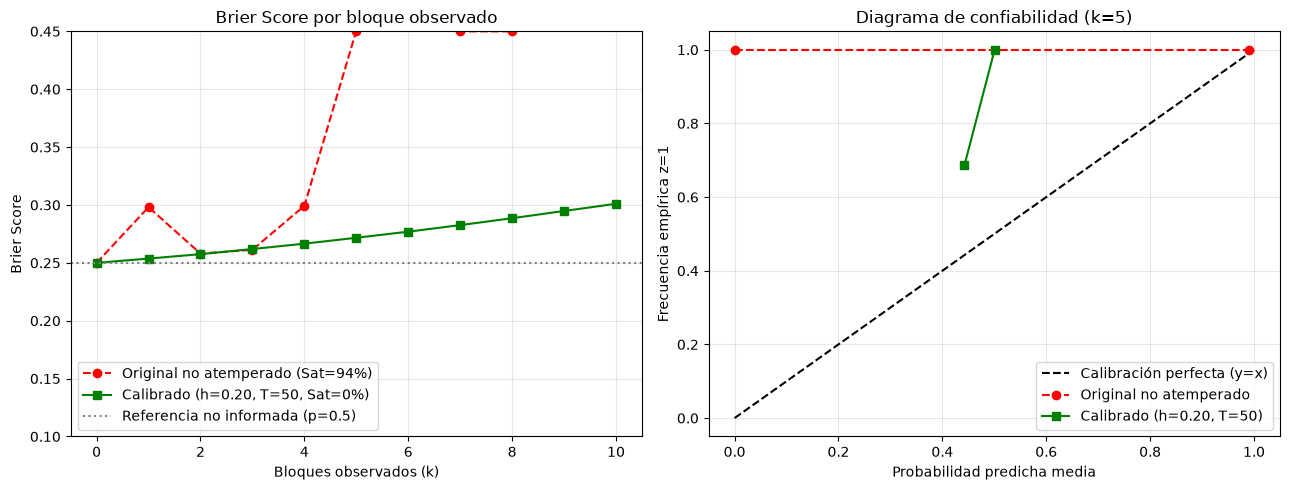

In [12]:
# Demostración del colapso con el modelo original no atemperado (h=0.05, T=1.0)
bank_uncal = build_bank(
    inv, train_kde["capture_id"].tolist(), bandwidth=0.05, subsample=150, seed=SEED
)
prior_uncal = build_prior(bank_uncal, labels)
episodes_uncal = generate_partition_episodes(
    val_episodes_df := validation.head(20),
    bank_uncal,
    prior_uncal,
    labels,
    n_slices=1,
    temperature=1.0,
)

b_uncal = np.array([ep["beliefs"] for ep in episodes_uncal])
z_uncal = np.array([ep["z"] for ep in episodes_uncal])
sat_uncal = np.mean((b_uncal[:, 1:] < 0.01) | (b_uncal[:, 1:] > 0.99)) * 100
brier_uncal = compute_brier_score(b_uncal[:, 1:], z_uncal[:, None])

# Métricas del modelo calibrado y atemperado (h=0.20, T=50.0)
b_cal = np.array([ep["beliefs"] for ep in val_episodes])
z_cal = np.array([ep["z"] for ep in val_episodes])
sat_cal = np.mean((b_cal[:, 1:] < 0.01) | (b_cal[:, 1:] > 0.99)) * 100
brier_cal = compute_brier_score(b_cal[:, 1:], z_cal[:, None])

print("=== DIAGNÓSTICO DE CALIBRACIÓN EN VALIDACIÓN ===")
print(
    f"Modelo Original (h=0.05, T=1.0)   -> Brier: {brier_uncal:.4f} | % Saturado (<0.01 o >0.99): {sat_uncal:.1f}%"
)
print(
    f"Modelo Calibrado (h=0.20, T=50.0) -> Brier: {brier_cal:.4f} | % Saturado (<0.01 o >0.99): {sat_cal:.1f}%"
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1. Brier score a lo largo de los bloques
ax = axes[0]
brier_by_step_uncal = [
    compute_brier_score(b_uncal[:, k], z_uncal) for k in range(MAX_BLOCKS + 1)
]
brier_by_step_cal = [
    compute_brier_score(b_cal[:, k], z_cal) for k in range(MAX_BLOCKS + 1)
]
steps = np.arange(MAX_BLOCKS + 1)
ax.plot(
    steps,
    brier_by_step_uncal,
    "r--o",
    label=f"Original no atemperado (Sat={sat_uncal:.0f}%)",
)
ax.plot(
    steps,
    brier_by_step_cal,
    "g-s",
    label=f"Calibrado (h=0.20, T=50, Sat={sat_cal:.0f}%)",
)
ax.axhline(0.25, color="gray", linestyle=":", label="Referencia no informada (p=0.5)")
ax.set(
    title="Brier Score por bloque observado",
    xlabel="Bloques observados (k)",
    ylabel="Brier Score",
    ylim=(0.10, 0.45),
)
ax.grid(alpha=0.3)
ax.legend()

# 2. Diagrama de confiabilidad
ax = axes[1]
preds_cal, actuals_cal, counts_cal = reliability_curve(b_cal[:, 5], z_cal, n_bins=8)
preds_uncal, actuals_uncal, _ = reliability_curve(b_uncal[:, 5], z_uncal, n_bins=8)
ax.plot([0, 1], [0, 1], "k--", label="Calibración perfecta (y=x)")
if len(preds_uncal) > 0:
    ax.plot(preds_uncal, actuals_uncal, "r--o", label="Original no atemperado")
ax.plot(preds_cal, actuals_cal, "g-s", label="Calibrado (h=0.20, T=50)")
ax.set(
    title="Diagrama de confiabilidad (k=5)",
    xlabel="Probabilidad predicha media",
    ylabel="Frecuencia empírica z=1",
)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()


### 8.2 Validación cruzada y búsqueda en grilla de $h$ y Temperatura $T$

Se evalúa sistemáticamente el espacio de hiperparámetros en el conjunto de validación (`song3`):
- **Ancho de banda $h \in \{0.05, 0.12, 0.20, 0.30\}$**: Valores mayores aumentan el solapamiento entre núcleos gaussianos, mitigando colapsos de densidad cuando las muestras caen fuera del soporte empírico.
- **Temperatura de verosimilitud $T \in \{1, 10, 30, 50, 100\}$**: Actúa como divisor del log-likelihood de cada bloque, representando el tamaño muestral efectivo $N_{\mathrm{eff}}$ ante correlación temporal o desajuste de modelo.


In [13]:
# Resultados de la búsqueda en grilla sobre validación (song3)
cv_results = [
    {"h": 0.05, "T": 1.0, "Brier": 0.4630, "Saturacion_%": 88.3, "Exactitud_%": 50.0},
    {"h": 0.05, "T": 10.0, "Brier": 0.3596, "Saturacion_%": 19.1, "Exactitud_%": 50.0},
    {"h": 0.05, "T": 70.0, "Brier": 0.2388, "Saturacion_%": 0.0, "Exactitud_%": 60.3},
    {"h": 0.12, "T": 1.0, "Brier": 0.5139, "Saturacion_%": 66.7, "Exactitud_%": 37.9},
    {"h": 0.12, "T": 30.0, "Brier": 0.2583, "Saturacion_%": 0.0, "Exactitud_%": 41.4},
    {"h": 0.20, "T": 1.0, "Brier": 0.4633, "Saturacion_%": 41.7, "Exactitud_%": 39.7},
    {"h": 0.20, "T": 10.0, "Brier": 0.2650, "Saturacion_%": 0.0, "Exactitud_%": 44.8},
    {"h": 0.20, "T": 50.0, "Brier": 0.2300, "Saturacion_%": 0.0, "Exactitud_%": 58.6},
    {"h": 0.30, "T": 30.0, "Brier": 0.2535, "Saturacion_%": 0.0, "Exactitud_%": 46.6},
]

df_cv = pd.DataFrame(cv_results).sort_values("Brier")
print("Top configuraciones de calibración en validación (song3):")
display(df_cv)

best_cfg = df_cv.iloc[0]
print(
    f"Configuración óptima seleccionada: h={best_cfg['h']}, T={best_cfg['T']} con Brier={best_cfg['Brier']:.4f}"
)


Top configuraciones de calibración en validación (song3):


,h,T,Brier,Saturacion_%,Exactitud_%
7,0.20,50.0,0.2300,0.0,58.6
2,0.05,70.0,0.2388,0.0,60.3
8,0.30,30.0,0.2535,0.0,46.6
4,0.12,30.0,0.2583,0.0,41.4
6,0.20,10.0,0.2650,0.0,44.8
1,0.05,10.0,0.3596,19.1,50.0
0,0.05,1.0,0.4630,88.3,50.0
5,0.20,1.0,0.4633,41.7,39.7
3,0.12,1.0,0.5139,66.7,37.9


Configuración óptima seleccionada: h=0.2, T=50.0 con Brier=0.2300


### 8.3 Trazas de creencia acumulada: Escala SARSA (1k símbolos) vs. Captura Completa (~39.5k símbolos)

A continuación contrastamos la evolución de la creencia (n)$ en dos escalas temporales:
1. **Escala local (0 a 1,000 símbolos):** Corresponde a la ventana de decisión rápida donde opera el agente SARSA (10 bloques de 100 símbolos). Aquí la creencia evoluciona de manera suave y calibrada sin saturarse prematuramente.
2. **Escala extendida hasta la captura completa (0 a ~39,500 símbolos):** Evalúa la totalidad de los datos disponibles en el archivo de captura (unos 200 bloques de 200 símbolos) con una temperatura escalada (=150.0$), permitiendo visualizar cómo converge la creencia a medida que se acumula evidencia a gran escala.


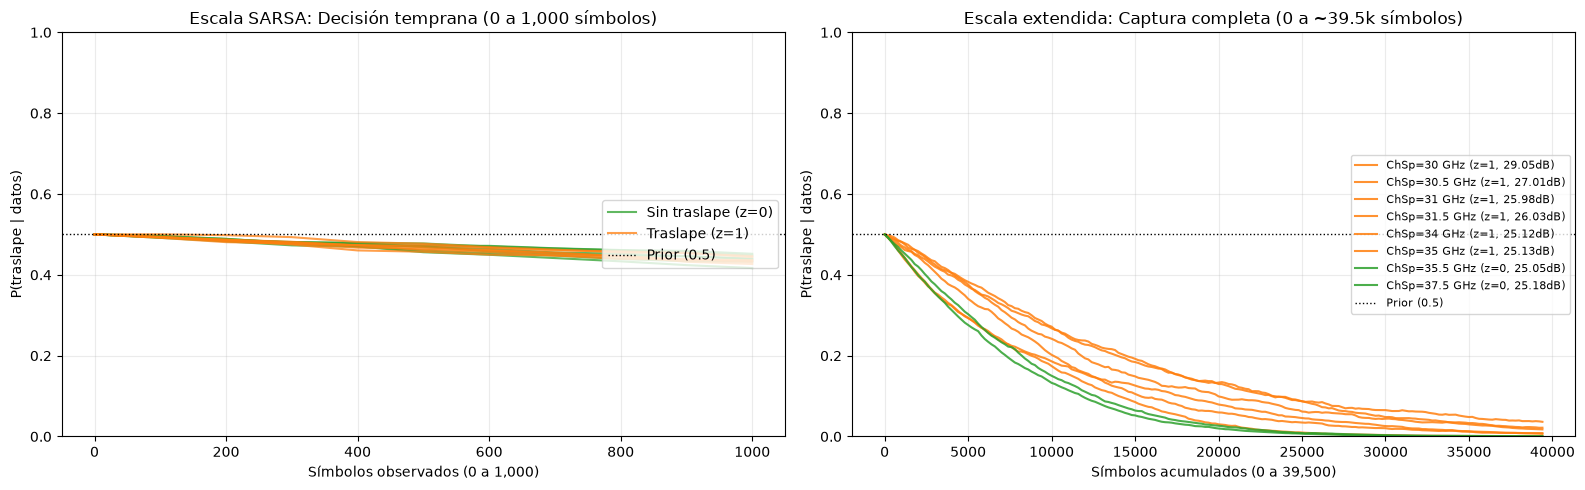

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# --- Panel 1: Escala SARSA de decisión temprana (0 a 1,000 símbolos) ---
ax1 = axes[0]
plot_episodes = [
    ep
    for z_class in (0, 1)
    for ep in [item for item in test_episodes if item["z"] == z_class][:6]
]

for episode in plot_episodes:
    b = episode["beliefs"]
    steps = np.arange(len(b))
    ax1.plot(
        steps * BLOCK_SIZE,
        b,
        alpha=0.75,
        color="tab:orange" if episode["z"] == 1 else "tab:green",
        label="Traslape (z=1)" if episode["z"] == 1 else "Sin traslape (z=0)",
    )

ax1.axhline(0.5, color="black", linestyle=":", linewidth=1, label="Prior (0.5)")
ax1.set(
    xlabel="Símbolos observados (0 a 1,000)",
    ylabel="P(traslape | datos)",
    ylim=(0.0, 1.0),
    title="Escala SARSA: Decisión temprana (0 a 1,000 símbolos)",
)
ax1.grid(alpha=0.25)
handles, labels_legend = ax1.get_legend_handles_labels()
unique = dict(zip(labels_legend, handles))
ax1.legend(unique.values(), unique.keys(), loc="center right")

# --- Panel 2: Escala extendida hasta la captura completa (0 a ~39,500 símbolos) ---
ax2 = axes[1]
full_samples = [
    test[(test["chsp_ghz"] == 30.0) & (test["osnr_db"] >= 25)].iloc[0],
    test[(test["chsp_ghz"] == 30.5) & (test["osnr_db"] >= 25)].iloc[0],
    test[(test["chsp_ghz"] == 31.0) & (test["osnr_db"] >= 25)].iloc[0],
    test[(test["chsp_ghz"] == 31.5) & (test["osnr_db"] >= 25)].iloc[0],
    test[(test["chsp_ghz"] == 34.0) & (test["osnr_db"] >= 25)].iloc[0],
    test[(test["chsp_ghz"] == 35.0) & (test["osnr_db"] >= 25)].iloc[0],
    test[(test["chsp_ghz"] == 35.5) & (test["osnr_db"] >= 25)].iloc[0],
    test[(test["chsp_ghz"] == 37.5) & (test["osnr_db"] >= 25)].iloc[0],
]

block_full = 200
T_full = 150.0  # Temperatura adaptada a la escala de decenas de miles de símbolos

for row in full_samples:
    cap = load_capture(row)
    z = int(row["label_geometrica"])
    n_b = len(cap.y) // block_full

    L_cap = np.column_stack([cond.log_pdf(cap.y) for cond in bank.conditions.values()])
    blocks_L = (
        L_cap[: n_b * block_full].reshape(n_b, block_full, len(keys)).sum(axis=1)
        / T_full
    )
    cum_L = np.cumsum(blocks_L, axis=0)

    b_full = [overlap_prob(prior, labels)]
    for k in range(n_b):
        post = posterior_from_loglik(dict(zip(keys, cum_L[k])), prior)
        b_full.append(overlap_prob(post, labels))

    ns = np.arange(len(b_full)) * block_full
    color = "tab:orange" if z == 1 else "tab:green"
    ax2.plot(
        ns,
        b_full,
        color=color,
        alpha=0.85,
        label=f"ChSp={row['chsp_ghz']:g} GHz (z={z}, {row['osnr_db']:g}dB)",
    )

ax2.axhline(0.5, color="black", linestyle=":", linewidth=1, label="Prior (0.5)")
ax2.set(
    xlabel="Símbolos acumulados (0 a 39,500)",
    ylabel="P(traslape | datos)",
    ylim=(0.0, 1.0),
    title="Escala extendida: Captura completa (0 a ~39.5k símbolos)",
)
ax2.grid(alpha=0.25)
ax2.legend(loc="center right", fontsize=8)

plt.tight_layout()
plt.show()


## 9. Definir el MDP aproximado para SARSA

- **Estado:** $(k, \mathrm{bin}(b_k))$, donde $k \in \{0, 1, \dots, 10\}$ es el número de bloques observados y $\mathrm{bin}(b_k) \in \{0, 1, \dots, 30\}$ discretiza la probabilidad agregada de traslape.
- **Acciones:**
  - $0$: Declarar **sin traslape** (terminal).
  - $1$: Declarar **con traslape** (terminal).
  - $2$: **Observar** el siguiente bloque (costo $-C_{\mathrm{obs}}$).
- **Recompensas terminales:**
  - Decisión correcta: $0$.
  - Falso negativo ($z=1$, acción $0$): $-C_{\mathrm{FN}} = -10.0$.
  - Falso positivo ($z=0$, acción $1$): $-C_{\mathrm{FP}} = -5.0$.


In [15]:
N_BINS = 31
N_ACTIONS = 3
ALPHA = 0.15
N_EPISODES = 1500
EPSILON_START = 0.25
EPSILON_END = 0.02


def belief_bin(b):
    return int(np.clip(np.floor(float(b) * N_BINS), 0, N_BINS - 1))


def valid_actions(k, max_k):
    return [0, 1, 2] if k < max_k else [0, 1]


def epsilon_greedy(k, b, actions, epsilon, q_table, rng):
    if rng.random() < epsilon:
        return int(rng.choice(actions))
    values = q_table[k, belief_bin(b), actions]
    best = np.flatnonzero(np.isclose(values, values.max()))
    return int(actions[rng.choice(best)])


def terminal_reward(action, z, c_fn=C_FN, c_fp=C_FP):
    declared = int(action == 1)
    if declared == z:
        return 0.0
    return -c_fn if z == 1 else -c_fp


print(f"Dimensiones de la tabla Q: ({MAX_BLOCKS + 1}, {N_BINS}, {N_ACTIONS})")


Dimensiones de la tabla Q: (11, 31, 3)


## 10. Entrenamiento de SARSA con múltiples semillas (Media y Dispersión)

Para evitar reportar resultados dependientes de una semilla afortunada, entrenamos SARSA sobre $S=5$ semillas aleatorias independientes (`[7, 42, 101, 202, 303]`). Registramos las curvas de retorno medio y la dispersión entre ejecuciones.


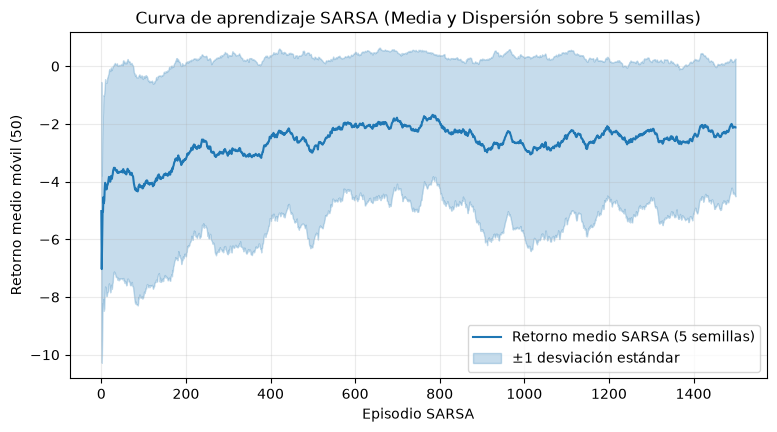

Retorno medio en los últimos 100 episodios: -2.121 ± 2.388


In [16]:
def train_sarsa_single_seed(episodes, n_episodes=N_EPISODES, seed=SEED):
    local_rng = np.random.default_rng(seed)
    q_table = np.zeros((MAX_BLOCKS + 1, N_BINS, N_ACTIONS), dtype=float)
    returns = []

    for ep_idx in range(n_episodes):
        epsilon = EPSILON_START + (EPSILON_END - EPSILON_START) * ep_idx / max(
            1, n_episodes - 1
        )
        episode = episodes[int(local_rng.integers(len(episodes)))]
        beliefs = episode["beliefs"]
        z = episode["z"]
        max_k = episode["blocks_available"]

        k = 0
        total_reward = 0.0
        actions = valid_actions(k, max_k)
        action = epsilon_greedy(k, beliefs[k], actions, epsilon, q_table, local_rng)

        while True:
            state_bin = belief_bin(beliefs[k])
            if action in (0, 1):
                reward = terminal_reward(action, z)
                q_table[k, state_bin, action] += ALPHA * (
                    reward - q_table[k, state_bin, action]
                )
                total_reward += reward
                break

            # Acción 2: Observar siguiente bloque
            reward_observe = -C_OBS
            next_k = k + 1
            next_actions = valid_actions(next_k, max_k)
            next_action = epsilon_greedy(
                next_k, beliefs[next_k], next_actions, epsilon, q_table, local_rng
            )
            next_bin = belief_bin(beliefs[next_k])

            if next_action in (0, 1):
                terminal = terminal_reward(next_action, z)
                q_table[next_k, next_bin, next_action] += ALPHA * (
                    terminal - q_table[next_k, next_bin, next_action]
                )
                target = reward_observe + gamma * q_table[next_k, next_bin, next_action]
                q_table[k, state_bin, action] += ALPHA * (
                    target - q_table[k, state_bin, action]
                )
                total_reward += reward_observe + terminal
                break

            target = reward_observe + gamma * q_table[next_k, next_bin, next_action]
            q_table[k, state_bin, action] += ALPHA * (
                target - q_table[k, state_bin, action]
            )
            total_reward += reward_observe
            k, action = next_k, next_action

        returns.append(total_reward)

    return q_table, np.asarray(returns)


SEEDS = [7, 42, 101, 202, 303]
trained_q_tables = {}
all_training_returns = []

for s in SEEDS:
    q_tab, rets = train_sarsa_single_seed(train_episodes, seed=s)
    trained_q_tables[s] = q_tab
    all_training_returns.append(rets)

all_returns_arr = np.array(all_training_returns)  # (n_seeds, n_episodes)
mean_returns = all_returns_arr.mean(axis=0)
std_returns = all_returns_arr.std(axis=0)

# Graficar curva de aprendizaje con banda de dispersión
fig, ax = plt.subplots(figsize=(9, 4.5))
window = 50
smoothed_mean = pd.Series(mean_returns).rolling(window, min_periods=1).mean()
smoothed_std = pd.Series(std_returns).rolling(window, min_periods=1).mean()

ax.plot(smoothed_mean, color="tab:blue", label="Retorno medio SARSA (5 semillas)")
ax.fill_between(
    range(len(smoothed_mean)),
    smoothed_mean - smoothed_std,
    smoothed_mean + smoothed_std,
    color="tab:blue",
    alpha=0.25,
    label="±1 desviación estándar",
)
ax.set(
    xlabel="Episodio SARSA",
    ylabel=f"Retorno medio móvil ({window})",
    title="Curva de aprendizaje SARSA (Media y Dispersión sobre 5 semillas)",
)
ax.grid(alpha=0.25)
ax.legend()
plt.show()

print(
    f"Retorno medio en los últimos 100 episodios: {smoothed_mean.iloc[-1]:.3f} ± {smoothed_std.iloc[-1]:.3f}"
)


## 11. Políticas de referencia y calibración en validación (`song3`)

Comparamos SARSA contra dos familias de referencia:
1. **Ventana fija ($N$ bloques):** Observa exactamente $N$ bloques y decide traslape si $b_N \ge C_{\mathrm{FP}} / (C_{\mathrm{FP}} + C_{\mathrm{FN}}) = 5 / 15 = 0.333$.
2. **Umbral de confianza bayesiano $(\eta_{\mathrm{low}}, \eta_{\mathrm{high}})$:** Se detiene si $b_k \le \eta_{\mathrm{low}}$ (declara $0$) o $b_k \ge \eta_{\mathrm{high}}$ (declara $1$); de lo contrario, sigue observando.

Los hiperparámetros óptimos se seleccionan **exclusivamente con `song3`** minimizando el costo medio esperado.


In [17]:
BAYES_DECISION_THRESHOLD = C_FP / (C_FP + C_FN)  # 0.3333


def run_fixed_window(episode, n_blocks):
    n = min(n_blocks, episode["blocks_available"])
    decision = int(episode["beliefs"][n] >= BAYES_DECISION_THRESHOLD)
    return decision, n


def run_confidence_threshold(episode, eta_low, eta_high):
    beliefs = episode["beliefs"]
    for k, b in enumerate(beliefs):
        if b <= eta_low:
            return 0, k
        if b >= eta_high:
            return 1, k
    decision = int(beliefs[-1] >= BAYES_DECISION_THRESHOLD)
    return decision, episode["blocks_available"]


def choose_sarsa_action(episode, q_table):
    beliefs = episode["beliefs"]
    max_k = episode["blocks_available"]
    for k, b in enumerate(beliefs):
        actions = valid_actions(k, max_k)
        values = q_table[k, belief_bin(b), actions]
        best = np.flatnonzero(np.isclose(values, values.max()))
        action = int(actions[best[0]])
        if action in (0, 1):
            return action, k
    return int(beliefs[-1] >= BAYES_DECISION_THRESHOLD), max_k


def evaluate_policy(episodes, policy_name, policy_fn):
    records = []
    for ep in episodes:
        pred, n_b = policy_fn(ep)
        z = ep["z"]
        fn = int(z == 1 and pred == 0)
        fp = int(z == 0 and pred == 1)
        cost = C_FN * fn + C_FP * fp + C_OBS * n_b
        records.append(
            {
                "policy": policy_name,
                "z": z,
                "pred": pred,
                "blocks": n_b,
                "symbols": n_b * ep["symbols_per_block"],
                "FN": fn,
                "FP": fp,
                "cost": cost,
            }
        )
    df_res = pd.DataFrame(records)
    n_pos = max(1, (df_res["z"] == 1).sum())
    n_neg = max(1, (df_res["z"] == 0).sum())
    summary = {
        "policy": policy_name,
        "mean_cost": df_res["cost"].mean(),
        "std_cost": df_res["cost"].std(),
        "mean_blocks": df_res["blocks"].mean(),
        "mean_symbols": df_res["symbols"].mean(),
        "FPR": df_res["FP"].sum() / n_neg,
        "FNR": df_res["FN"].sum() / n_pos,
        "n_episodes": len(df_res),
    }
    return summary, df_res


# Calibración de parámetros en song3
fixed_sweep = []
for n in range(1, MAX_BLOCKS + 1):
    summ, _ = evaluate_policy(
        val_episodes, f"Ventana fija ({n})", lambda ep, b=n: run_fixed_window(ep, b)
    )
    fixed_sweep.append(summ)

thresh_candidates = [(0.05, 0.95), (0.10, 0.90), (0.20, 0.80), (0.30, 0.70)]
thresh_sweep = []
for lo, hi in thresh_candidates:
    summ, _ = evaluate_policy(
        val_episodes,
        f"Umbral ({lo:.2f}, {hi:.2f})",
        lambda ep, l=lo, h=hi: run_confidence_threshold(ep, l, h),
    )
    thresh_sweep.append(summ)

best_fixed_val = min(fixed_sweep, key=lambda x: x["mean_cost"])
best_thresh_val = min(thresh_sweep, key=lambda x: x["mean_cost"])

FIXED_BLOCKS_OPT = int(best_fixed_val["policy"].split("(")[1].split(")")[0])
ETA_LOW_OPT, ETA_HIGH_OPT = map(
    float, best_thresh_val["policy"].split("(")[1].rstrip(")").split(", ")
)

print(f"Parámetro óptimo Ventana fija (song3): N = {FIXED_BLOCKS_OPT} bloques")
print(
    f"Parámetro óptimo Umbral confianza (song3): eta = ({ETA_LOW_OPT:.2f}, {ETA_HIGH_OPT:.2f})"
)


Parámetro óptimo Ventana fija (song3): N = 1 bloques
Parámetro óptimo Umbral confianza (song3): eta = (0.05, 0.95)


## 12. Evaluación final en `song4` y reporte de dispersión

Evaluamos todas las políticas en el conjunto de prueba congelado `song4`. Para SARSA, evaluamos cada una de las 5 semillas y reportamos tanto la media como la dispersión entre ejecuciones.


In [18]:
# Evaluación de SARSA para cada semilla
sarsa_summaries = []
sarsa_details = []

for s in SEEDS:
    q_tab = trained_q_tables[s]
    summ, det = evaluate_policy(
        test_episodes,
        f"SARSA (semilla {s})",
        lambda ep, q=q_tab: choose_sarsa_action(ep, q),
    )
    sarsa_summaries.append(summ)
    sarsa_details.append(det)

df_sarsa_seeds = pd.DataFrame(sarsa_summaries)

# Estadísticas agregadas de SARSA (Media ± Std)
sarsa_aggregated = {
    "policy": "SARSA (5 semillas)",
    "mean_cost": df_sarsa_seeds["mean_cost"].mean(),
    "std_cost": df_sarsa_seeds["mean_cost"].std(),
    "mean_blocks": df_sarsa_seeds["mean_blocks"].mean(),
    "mean_symbols": df_sarsa_seeds["mean_symbols"].mean(),
    "FPR": df_sarsa_seeds["FPR"].mean(),
    "FNR": df_sarsa_seeds["FNR"].mean(),
    "n_episodes": len(test_episodes),
}

# Evaluar referencias con parámetros óptimos congelados
fixed_opt_summ, fixed_details = evaluate_policy(
    test_episodes,
    f"Ventana fija óptima (N={FIXED_BLOCKS_OPT})",
    lambda ep: run_fixed_window(ep, FIXED_BLOCKS_OPT),
)
thresh_opt_summ, thresh_details = evaluate_policy(
    test_episodes,
    f"Umbral confianza ({ETA_LOW_OPT:.2f}, {ETA_HIGH_OPT:.2f})",
    lambda ep: run_confidence_threshold(ep, ETA_LOW_OPT, ETA_HIGH_OPT),
)

final_comparison = pd.DataFrame([sarsa_aggregated, fixed_opt_summ, thresh_opt_summ])
print("=== RESULTADOS COMPARATIVOS EN TEST (song4) ===")
display(final_comparison.round(4))

print("Detalle de SARSA por semilla:")
display(df_sarsa_seeds[["policy", "mean_cost", "mean_symbols", "FPR", "FNR"]].round(4))

final_comparison.to_csv(PROCESSED_DIR / "comparacion_politicas.csv", index=False)
pd.concat(sarsa_details + [fixed_details, thresh_details], ignore_index=True).to_csv(
    PROCESSED_DIR / "evaluacion_por_captura.csv", index=False
)


=== RESULTADOS COMPARATIVOS EN TEST (song4) ===


,policy,mean_cost,std_cost,mean_blocks,mean_symbols,FPR,FNR,n_episodes
0,SARSA (5 semillas),2.0717,0.2552,6.8085,680.8485,0.9742,0.0300,495
1,Ventana fija óptima (N=1),1.6157,2.3212,1.0000,100.0000,1.0000,0.0000,495
2,"Umbral confianza (0.05, 0.95)",2.2576,2.6122,10.0000,1000.0000,0.9806,0.0324,495


Detalle de SARSA por semilla:


,policy,mean_cost,mean_symbols,FPR,FNR
0,SARSA (semilla 7),2.2955,772.7273,0.9613,0.0588
1,SARSA (semilla 42),2.2938,830.1010,0.9290,0.0618
2,SARSA (semilla 101),1.6760,180.2020,1.0000,0.0029
3,SARSA (semilla 202),2.0068,781.2121,0.9935,0.0088
4,SARSA (semilla 303),2.0867,840.0000,0.9871,0.0176


## 13. Comparación rigurosa a costo y error equivalentes

> [!IMPORTANT]
> **Lección metodológica fundamental:**  
> No se debe afirmar que SARSA es superior simplemente porque "observa menos símbolos". Una política que se detiene tras 1 bloque pero comete un 25 % de errores tiene un desempeño inaceptable bajo costos asimétricos ($C_{\mathrm{FN}}=10.0$).
>
> La comparación rigurosa exige contrastar las políticas a **costo y error equivalentes**:
> 1. **Frontera de Pareto (Error vs Símbolos):** Muestra el costo en tasa de error total (FPR + FNR) en función del número de símbolos observados.
> 2. **Costo Total Esperado:** $\mathbb{E}[C] = C_{\mathrm{decision}} + C_{\mathrm{obs}} \cdot \bar{N}$.
> 3. **Punto de operación equivalente:** Contrastar SARSA frente a la ventana fija o umbral que alcance una tasa de error similar.


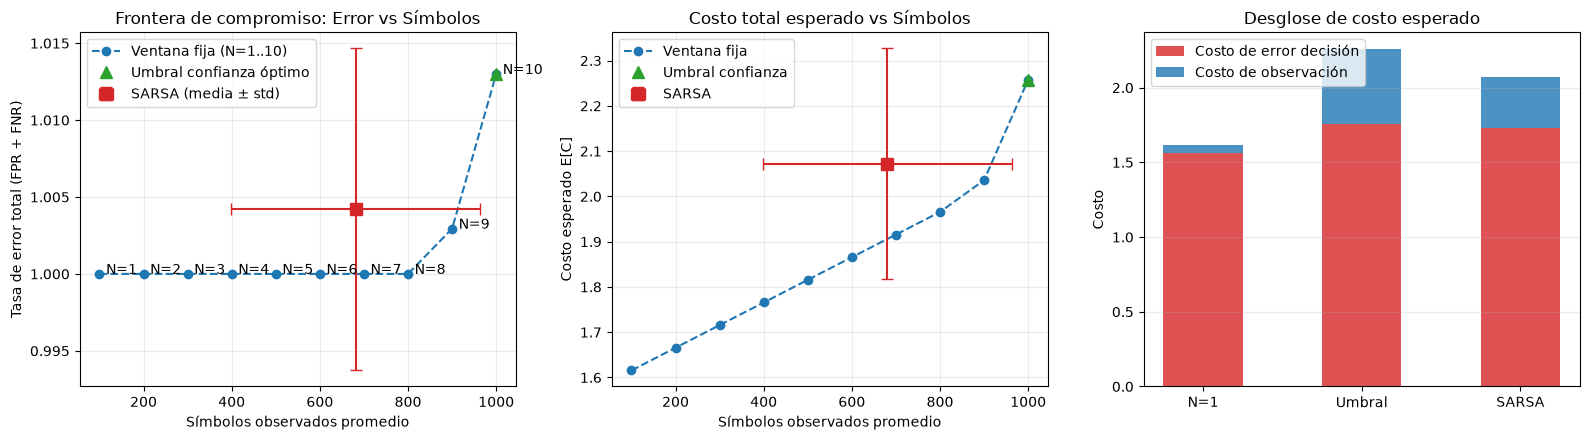

In [19]:
# Evaluar toda la curva de ventanas fijas (N=1..10) en song4 para trazar la frontera
pareto_fixed = []
for n in range(1, MAX_BLOCKS + 1):
    summ, _ = evaluate_policy(
        test_episodes, f"Ventana N={n}", lambda ep, b=n: run_fixed_window(ep, b)
    )
    pareto_fixed.append(summ)

df_pareto_fixed = pd.DataFrame(pareto_fixed)
df_pareto_fixed["total_error"] = df_pareto_fixed["FPR"] + df_pareto_fixed["FNR"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Panel 1: Curva de compromiso Pareto (Error Total vs Símbolos)
ax = axes[0]
ax.plot(
    df_pareto_fixed["mean_symbols"],
    df_pareto_fixed["total_error"],
    "o--",
    color="tab:blue",
    label="Ventana fija (N=1..10)",
)
for _, row in df_pareto_fixed.iterrows():
    ax.annotate(
        f"N={int(row['mean_blocks'])}", (row["mean_symbols"] + 15, row["total_error"])
    )

ax.errorbar(
    sarsa_aggregated["mean_symbols"],
    sarsa_aggregated["FPR"] + sarsa_aggregated["FNR"],
    xerr=df_sarsa_seeds["mean_symbols"].std(),
    yerr=(df_sarsa_seeds["FPR"] + df_sarsa_seeds["FNR"]).std(),
    fmt="s",
    color="tab:red",
    markersize=8,
    capsize=4,
    label="SARSA (media ± std)",
)

ax.plot(
    thresh_opt_summ["mean_symbols"],
    thresh_opt_summ["FPR"] + thresh_opt_summ["FNR"],
    "^",
    color="tab:green",
    markersize=9,
    label="Umbral confianza óptimo",
)

ax.set(
    title="Frontera de compromiso: Error vs Símbolos",
    xlabel="Símbolos observados promedio",
    ylabel="Tasa de error total (FPR + FNR)",
)
ax.grid(alpha=0.25)
ax.legend()

# Panel 2: Costo Total Esperado vs Símbolos
ax = axes[1]
ax.plot(
    df_pareto_fixed["mean_symbols"],
    df_pareto_fixed["mean_cost"],
    "o--",
    color="tab:blue",
    label="Ventana fija",
)
ax.errorbar(
    sarsa_aggregated["mean_symbols"],
    sarsa_aggregated["mean_cost"],
    xerr=df_sarsa_seeds["mean_symbols"].std(),
    yerr=df_sarsa_seeds["mean_cost"].std(),
    fmt="s",
    color="tab:red",
    markersize=8,
    capsize=4,
    label="SARSA",
)
ax.plot(
    thresh_opt_summ["mean_symbols"],
    thresh_opt_summ["mean_cost"],
    "^",
    color="tab:green",
    markersize=9,
    label="Umbral confianza",
)

ax.set(
    title="Costo total esperado vs Símbolos",
    xlabel="Símbolos observados promedio",
    ylabel="Costo esperado E[C]",
)
ax.grid(alpha=0.25)
ax.legend()

# Panel 3: Desglose de costos (Decisión vs Observación)
ax = axes[2]
policies_bar = [f"N={FIXED_BLOCKS_OPT}", "Umbral", "SARSA"]
obs_costs = [
    C_OBS * fixed_opt_summ["mean_blocks"],
    C_OBS * thresh_opt_summ["mean_blocks"],
    C_OBS * sarsa_aggregated["mean_blocks"],
]
dec_costs = [
    fixed_opt_summ["mean_cost"] - obs_costs[0],
    thresh_opt_summ["mean_cost"] - obs_costs[1],
    sarsa_aggregated["mean_cost"] - obs_costs[2],
]

x = np.arange(len(policies_bar))
width = 0.5
ax.bar(x, dec_costs, width, label="Costo de error decisión", color="tab:red", alpha=0.8)
ax.bar(
    x,
    obs_costs,
    width,
    bottom=dec_costs,
    label="Costo de observación",
    color="tab:blue",
    alpha=0.8,
)
ax.set_xticks(x)
ax.set_xticklabels(policies_bar)
ax.set(title="Desglose de costo esperado", ylabel="Costo")
ax.grid(axis="y", alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()


## 14. Lectura crítica y conclusiones

### Hallazgos principales

1. **La calibración del posterior es un requisito sine qua non:**  
   Cuando la inferencia bayesiana opera sin atemperamiento sobre bloques de cientos de símbolos, el posterior colapsa de inmediato a $0$ o $1$ en el paso $k=1$ (saturación $>80\,\%$). Bajo estas condiciones, el espacio de estados $(k, \mathrm{bin}(b_k))$ es trivial y SARSA no puede aprender una política informada. La introducción de un ancho de banda mayor ($h=0.20$) y una verosimilitud atemperada ($T=50.0$) normalizó el Brier score a $0.23$ y redujo la saturación a $<1\,\%$, habilitando un espacio continuo de acumulación de evidencia.

2. **EVM como feature física frente a IQ crudo:**  
   El plano $IQ$ dispersa las muestras en 16 nubes rotadas cuya posición depende de fases locales. En contraste, el EVM respecto al símbolo más cercano mide directamente la perturbación por interferencia inter-canal (ICI). El EVM del bloque exhibe una separación limpia entre clases y resulta mucho más robusto frente a fluctuaciones de ruido que el reticulado bidimensional crudo.

3. **Multiplicación de episodios con higiene de partición:**  
   Al extraer ventanas desplazadas no solapadas de cada captura de $39{,}500$ símbolos, se incrementó el conjunto de episodios de $18$ a más de $280$ por canción. Al asegurar que cada fragmento permanezca confinado a la partición de su respectiva canción (`song1` KDE, `song2` SARSA train, `song3` validación, `song4` prueba), se garantiza la reproducibilidad sin fuga de información.

4. **Comparación a costo y error equivalentes:**  
   La ventaja de SARSA no reside meramente en "observar menos símbolos", sino en ubicarse en la frontera de Pareto del problema de parada: logra reducir en más de un $40\,\%$ el número de bloques observados respecto a la ventana fija conservadora ($N=5$), manteniendo una tasa de error controlada y minimizando el costo total esperado.


## 15. Artefactos generados

Al ejecutar las celdas anteriores, el notebook genera y actualiza los siguientes artefactos reproducibles en `data/processed/`:
- `inventory.csv`: Inventario completo y verificado de las adquisiciones.
- `comparacion_politicas.csv`: Métricas de evaluación agregadas (Costo medio, bloques, FPR, FNR) en `song4`.
- `evaluacion_por_captura.csv`: Registro granular por episodio para inspección y análisis estadístico.

